# 딥러닝의 이해 과제2
## 202110942 정주연

## 1. Fashion-MNIST

### 1.1. Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

# Load dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

### 1.2. Exploratory Data Analysis (EDA)

#### 1.2.1. Dataset Overview

In [2]:
# Dataset information
print("=== Dataset Information ===")
print(f"Training images: {x_train.shape}")
print(f"Test images: {x_test.shape}")
print(f"Data type: {x_train.dtype}")

# Pixel statistics
print("\n=== Pixel Statistics ===")
print(f"Minimum: {x_train.min()}")
print(f"Maximum: {x_train.max()}")

# Missing values
print("\n=== Missing Values ===")
print(f"Training: {np.isnan(x_train).sum()}")
print(f"Test: {np.isnan(x_test).sum()}")

# Number of classes
print("\n=== Number of Classes ===")
print(len(np.unique(y_train)))

=== Dataset Information ===
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Data type: uint8

=== Pixel Statistics ===
Minimum: 0
Maximum: 255

=== Missing Values ===
Training: 0
Test: 0

=== Number of Classes ===
10


#### 1.2.2. Class Distribution

In [3]:
# Class distribution
class_distribution = pd.DataFrame({
    'Class': class_names,
    'Train Count': np.bincount(y_train),
    'Test Count': np.bincount(y_test)
})

print("=== Class Distribution ===")
print(class_distribution.to_string(index=False))

=== Class Distribution ===
      Class  Train Count  Test Count
T-shirt/top         6000        1000
    Trouser         6000        1000
   Pullover         6000        1000
      Dress         6000        1000
       Coat         6000        1000
     Sandal         6000        1000
      Shirt         6000        1000
    Sneaker         6000        1000
        Bag         6000        1000
 Ankle boot         6000        1000


#### 1.2.3. Sample Visualization

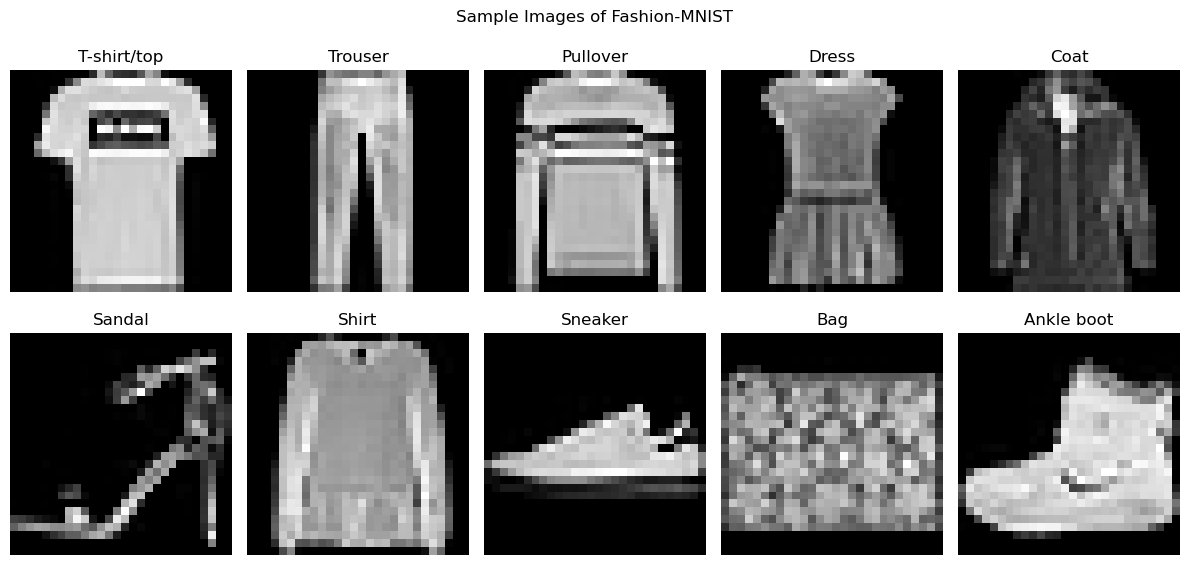

In [4]:
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    idx = np.where(y_train == i)[0][0]

    ax.imshow(x_train[idx], cmap='gray')
    ax.set_title(class_names[i])
    ax.axis('off')

plt.suptitle('Sample Images of Fashion-MNIST')
plt.tight_layout()
plt.show()

#### 1.2.4. EDA Results

각 클래스의 데이터가 균등하게 분포하여 별도의 클래스 불균형 보정은 필요하지 않다. 다만 일부 상의 클래스는 형태가 유사하여 분류 과정에서 혼동될 가능성이 있으므로, 모델 학습 후 혼동행렬을 통해 오분류 양상을 확인한다.

### 1.3. Data Preprocessing

픽셀값을 0~1 범위로 정규화하고, 모델의 입력 구조에 맞게 데이터를 변환한다. DNN은 이미지를 784차원 벡터로 변환하며, CNN은 공간적 특징을 학습할 수 있도록 28×28×1 형태를 유지한다.

In [5]:
# Normalize pixel values
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

# Prepare inputs for DNN
x_train_dnn = x_train_norm.reshape(-1, 784)
x_test_dnn = x_test_norm.reshape(-1, 784)

# Prepare inputs for CNN
x_train_cnn = x_train_norm[..., np.newaxis]
x_test_cnn = x_test_norm[..., np.newaxis]

### 1.4. Cross-Validation Strategy

In [6]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

fold_indices = list(skf.split(x_train_dnn, y_train))

### 1.5. DNN Model

#### 1.5.1. Model Architecture

Fashion-MNIST 이미지 분류를 위해 두 개의 은닉층(256, 128)으로 구성된 DNN을 설계하였다. 각 은닉층에는 ReLU 활성화 함수를 적용하고, 출력층에는 10개 클래스의 분류 확률을 계산하기 위해 Softmax 함수를 사용하였다.

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Baseline DNN model
def build_dnn():
    model = models.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Model architecture
dnn = build_dnn()
dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

#### 1.5.2. Model Training and Cross-Validation

In [8]:
from sklearn.model_selection import train_test_split

# Baseline DNN: 10-Fold Cross-Validation
EPOCHS = 30
BATCH_SIZE = 128

dnn_cv_results = []
dnn_histories = []

for fold, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"\n===== Fold {fold}/10 =====")

    # Reset model
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = x_train_dnn[train_idx]
    y_fold_train = y_train[train_idx]

    x_fold_val = x_train_dnn[val_idx]
    y_fold_val = y_train[val_idx]

    # Separate data for Early Stopping
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_dnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate on CV fold
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    dnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    dnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")


===== Fold 1/10 =====

Validation Accuracy: 0.8983
Validation Loss: 0.2905

===== Fold 2/10 =====
Validation Accuracy: 0.8842
Validation Loss: 0.3256

===== Fold 3/10 =====
Validation Accuracy: 0.8812
Validation Loss: 0.3344

===== Fold 4/10 =====
Validation Accuracy: 0.8757
Validation Loss: 0.3467

===== Fold 5/10 =====
Validation Accuracy: 0.8892
Validation Loss: 0.3094

===== Fold 6/10 =====
Validation Accuracy: 0.8870
Validation Loss: 0.3399

===== Fold 7/10 =====
Validation Accuracy: 0.8842
Validation Loss: 0.3343

===== Fold 8/10 =====
Validation Accuracy: 0.8827
Validation Loss: 0.3194

===== Fold 9/10 =====
Validation Accuracy: 0.8892
Validation Loss: 0.3088

===== Fold 10/10 =====
Validation Accuracy: 0.8803
Validation Loss: 0.3425


#### 1.5.3. Cross-Validation Results

In [9]:
# Cross-validation results
dnn_cv_df = pd.DataFrame(dnn_cv_results)

print("=== DNN 10-Fold Cross-Validation Results ===")
print(dnn_cv_df.round(4).to_string(index=False))

print("\n=== Summary ===")
print(f"Mean Accuracy: {dnn_cv_df['Accuracy'].mean():.4f}")
print(f"Std Accuracy : {dnn_cv_df['Accuracy'].std():.4f}")
print(f"Mean Loss    : {dnn_cv_df['Loss'].mean():.4f}")
print(f"Std Loss     : {dnn_cv_df['Loss'].std():.4f}")

=== DNN 10-Fold Cross-Validation Results ===
 Fold   Loss  Accuracy  Epochs
    1 0.2905    0.8983      15
    2 0.3256    0.8842      10
    3 0.3344    0.8812      10
    4 0.3467    0.8757      13
    5 0.3094    0.8892      13
    6 0.3399    0.8870      16
    7 0.3343    0.8842      16
    8 0.3194    0.8827      11
    9 0.3088    0.8892      11
   10 0.3425    0.8803      11

=== Summary ===
Mean Accuracy: 0.8852
Std Accuracy : 0.0062
Mean Loss    : 0.3251
Std Loss     : 0.0179


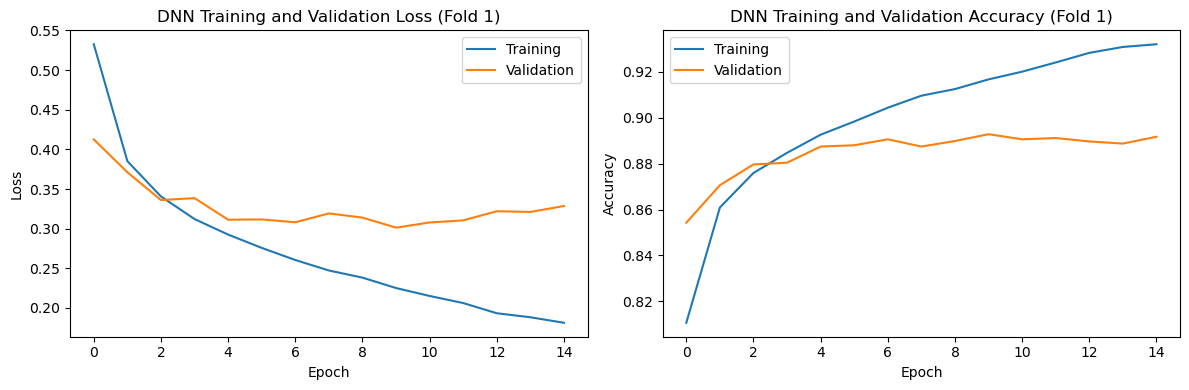

In [10]:
# Training history (Fold 1)
history = dnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history['loss'], label='Training')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('DNN Training and Validation Loss (Fold 1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history['accuracy'], label='Training')
axes[1].plot(history['val_accuracy'], label='Validation')
axes[1].set_title('DNN Training and Validation Accuracy (Fold 1)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 1.5.4. DNN Optimization

기본 DNN의 학습 곡선에서 과적합 징후가 관찰되어 두 번째 은닉층 뒤에 Dropout(0.25)을 적용하였다. 동일한 10-Fold 교차검증을 통해 정규화 적용 전후의 성능을 비교하였다.

In [11]:
# Optimized DNN model
def build_optimized_dnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

optimized_dnn = build_optimized_dnn()
optimized_dnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Optimized DNN: 10-Fold Cross-Validation
optimized_dnn_cv_results = []
optimized_dnn_histories = []

for fold, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"\n===== Optimized DNN: Fold {fold}/10 =====")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = x_train_dnn[train_idx]
    y_fold_train = y_train[train_idx]

    x_fold_val = x_train_dnn[val_idx]
    y_fold_val = y_train[val_idx]

    # Internal validation set for Early Stopping
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_optimized_dnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate on CV fold
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    optimized_dnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    optimized_dnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")


===== Optimized DNN: Fold 1/10 =====
Validation Accuracy: 0.8962
Validation Loss: 0.2874

===== Optimized DNN: Fold 2/10 =====
Validation Accuracy: 0.8818
Validation Loss: 0.3258

===== Optimized DNN: Fold 3/10 =====
Validation Accuracy: 0.8868
Validation Loss: 0.3229

===== Optimized DNN: Fold 4/10 =====
Validation Accuracy: 0.8892
Validation Loss: 0.3217

===== Optimized DNN: Fold 5/10 =====
Validation Accuracy: 0.8828
Validation Loss: 0.3126

===== Optimized DNN: Fold 6/10 =====
Validation Accuracy: 0.8793
Validation Loss: 0.3371

===== Optimized DNN: Fold 7/10 =====
Validation Accuracy: 0.8862
Validation Loss: 0.3151

===== Optimized DNN: Fold 8/10 =====
Validation Accuracy: 0.8927
Validation Loss: 0.3103

===== Optimized DNN: Fold 9/10 =====
Validation Accuracy: 0.8928
Validation Loss: 0.3084

===== Optimized DNN: Fold 10/10 =====
Validation Accuracy: 0.8857
Validation Loss: 0.3275


#### 1.5.5. DNN Model Comparison

In [13]:
# Optimized DNN results
optimized_dnn_cv_df = pd.DataFrame(optimized_dnn_cv_results)

print("=== Optimized DNN 10-Fold Results ===")
print(optimized_dnn_cv_df.round(4).to_string(index=False))

# Model comparison
dnn_comparison = pd.DataFrame({
    'Model': ['Baseline DNN', 'Optimized DNN'],
    'Mean Accuracy': [
        dnn_cv_df['Accuracy'].mean(),
        optimized_dnn_cv_df['Accuracy'].mean()
    ],
    'Std Accuracy': [
        dnn_cv_df['Accuracy'].std(),
        optimized_dnn_cv_df['Accuracy'].std()
    ],
    'Mean Loss': [
        dnn_cv_df['Loss'].mean(),
        optimized_dnn_cv_df['Loss'].mean()
    ],
    'Std Loss': [
        dnn_cv_df['Loss'].std(),
        optimized_dnn_cv_df['Loss'].std()
    ]
})

print("\n=== DNN Model Comparison ===")
print(dnn_comparison.round(4).to_string(index=False))

=== Optimized DNN 10-Fold Results ===
 Fold   Loss  Accuracy  Epochs
    1 0.2874    0.8962      14
    2 0.3258    0.8818      13
    3 0.3229    0.8868      15
    4 0.3217    0.8892      21
    5 0.3126    0.8828      12
    6 0.3371    0.8793      11
    7 0.3151    0.8862      16
    8 0.3103    0.8927      17
    9 0.3084    0.8928      13
   10 0.3275    0.8857      12

=== DNN Model Comparison ===
        Model  Mean Accuracy  Std Accuracy  Mean Loss  Std Loss
 Baseline DNN         0.8852        0.0062     0.3251    0.0179
Optimized DNN         0.8873        0.0054     0.3169    0.0136


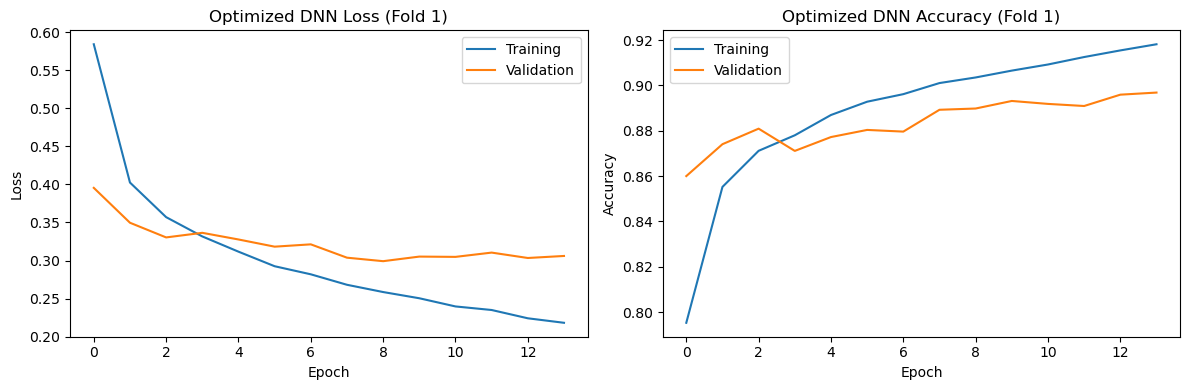

In [14]:
# Optimized DNN training history (Fold 1)
history = optimized_dnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history['loss'], label='Training')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('Optimized DNN Loss (Fold 1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history['accuracy'], label='Training')
axes[1].plot(history['val_accuracy'], label='Validation')
axes[1].set_title('Optimized DNN Accuracy (Fold 1)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 1.5.6. DNN Optimization Results

Stratified 10-Fold 교차검증 결과, Dropout(0.25)을 적용한 DNN의 평균 정확도는 88.73%로 기본 DNN(88.52%)보다 0.21%p 높게 나타났다. 평균 손실과 Fold 간 성능 변동도 소폭 감소하여 전반적인 성능이 개선되는 경향을 보였다.

다만 정확도 차이가 크지 않아 뚜렷한 성능 향상으로 단정하기는 어렵다. 따라서 동일한 파라미터 수에서 상대적으로 양호한 결과를 보인 Dropout DNN을 최종 모델 후보로 선정하였다.

#### 1.5.7. Final DNN Evaluation

In [15]:
# Select final training epochs from CV histories
best_epochs = [
    int(np.argmin(history['val_loss']) + 1)
    for history in optimized_dnn_histories
]

final_epochs = int(np.median(best_epochs))

print("Best Epochs:", best_epochs)
print("Selected Epochs:", final_epochs)

# Final DNN training
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

final_dnn = build_optimized_dnn()

final_dnn_history = final_dnn.fit(
    x_train_dnn,
    y_train,
    epochs=final_epochs,
    batch_size=BATCH_SIZE,
    verbose=1
)

Best Epochs: [9, 8, 10, 16, 7, 6, 11, 12, 8, 7]
Selected Epochs: 8
Epoch 1/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8076 - loss: 0.5476
Epoch 2/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8603 - loss: 0.3868
Epoch 3/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8752 - loss: 0.3442
Epoch 4/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8816 - loss: 0.3220
Epoch 5/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8896 - loss: 0.3017
Epoch 6/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8937 - loss: 0.2875
Epoch 7/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8991 - loss: 0.2751
Epoch 8/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9028 - loss: 0.2607


In [16]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

# Test predictions
y_prob_dnn = final_dnn.predict(x_test_dnn, verbose=0)
y_pred_dnn = np.argmax(y_prob_dnn, axis=1)

# Overall evaluation
test_loss, test_accuracy = final_dnn.evaluate(
    x_test_dnn,
    y_test,
    verbose=0
)

print("=== Final DNN Test Results ===")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss    : {test_loss:.4f}")

# Class-wise classification results
print("\n=== Classification Report ===")
print(
    classification_report(
        y_test,
        y_pred_dnn,
        target_names=class_names,
        digits=4
    )
)

=== Final DNN Test Results ===
Test Accuracy: 0.8843
Test Loss    : 0.3299

=== Classification Report ===
              precision    recall  f1-score   support

 T-shirt/top     0.8282    0.8630    0.8452      1000
     Trouser     0.9848    0.9730    0.9789      1000
    Pullover     0.8175    0.7570    0.7861      1000
       Dress     0.8885    0.9000    0.8942      1000
        Coat     0.7862    0.8310    0.8080      1000
      Sandal     0.9716    0.9590    0.9653      1000
       Shirt     0.6915    0.6970    0.6942      1000
     Sneaker     0.9452    0.9480    0.9466      1000
         Bag     0.9969    0.9520    0.9739      1000
  Ankle boot     0.9432    0.9630    0.9530      1000

    accuracy                         0.8843     10000
   macro avg     0.8853    0.8843    0.8845     10000
weighted avg     0.8853    0.8843    0.8845     10000



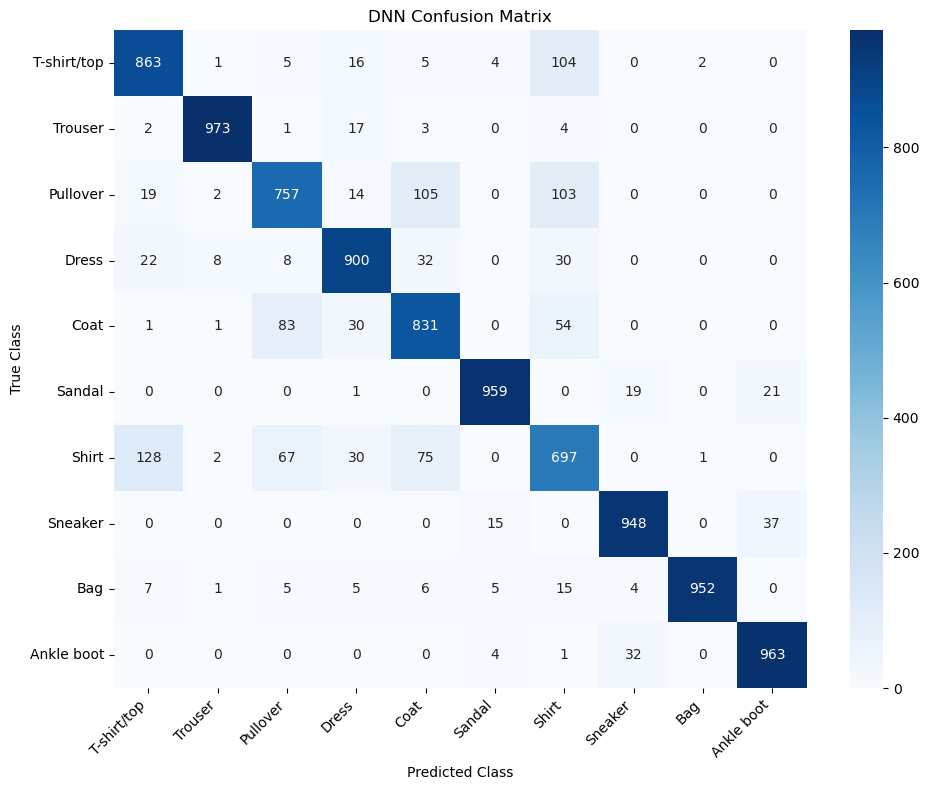

In [17]:
import seaborn as sns

# Confusion matrix
cm_dnn = confusion_matrix(y_test, y_pred_dnn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_dnn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('DNN Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Save final DNN results
from sklearn.metrics import precision_score, recall_score, f1_score

dnn_final_results = {
    'Model': 'DNN',
    'Accuracy': accuracy_score(y_test, y_pred_dnn),
    'Precision': precision_score(
        y_test, y_pred_dnn, average='macro'
    ),
    'Recall': recall_score(
        y_test, y_pred_dnn, average='macro'
    ),
    'F1-score': f1_score(
        y_test, y_pred_dnn, average='macro'
    ),
    'Parameters': final_dnn.count_params()
}

#### 1.5.8. Final DNN Results

Dropout(0.25)을 적용한 DNN의 최종 테스트 정확도는 88.43%, Macro F1-score는 88.45%로 나타났다. 이는 10-Fold 교차검증 평균 정확도(88.73%)와 유사한 수준으로, 교차검증 결과와 최종 테스트 성능이 대체로 일치하였다.

클래스별 성능 분석에서는 Trouser, Bag, Sandal 등이 높은 분류 성능을 보인 반면, Shirt와 Pullover는 상대적으로 낮은 F1-score를 기록하였다. 혼동행렬에서도 Shirt, T-shirt/top, Pullover, Coat 등 형태가 유사한 상의 클래스 간 오분류가 집중적으로 나타났다.

이러한 결과를 바탕으로 이후 CNN 모델에서 이미지의 공간적 특징을 학습하는 것이 분류 성능, 특히 유사한 클래스 간 구분에 어떤 영향을 미치는지 비교한다.

### 1.6. CNN Model

#### 1.6.1. Model Architecture

이미지의 공간적 특징을 학습하기 위해 두 개의 Conv2D 계층과 MaxPooling2D 계층으로 구성된 CNN을 설계하였다. 합성곱 계층에서 특징을 추출한 후 Flatten과 완전연결 계층을 통해 10개 클래스를 분류하도록 구성하였다.

In [19]:
# Baseline CNN model
def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),

        tf.keras.layers.Conv2D(
            32, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            64, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Model architecture
cnn = build_cnn()
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

#### 1.6.2. Model Training and Cross-Validation

In [20]:
# Baseline CNN: 10-Fold Cross-Validation
cnn_cv_results = []
cnn_histories = []

for fold, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"\n===== CNN: Fold {fold}/10 =====")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = x_train_cnn[train_idx]
    y_fold_train = y_train[train_idx]

    x_fold_val = x_train_cnn[val_idx]
    y_fold_val = y_train[val_idx]

    # Internal validation set for Early Stopping
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_cnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate on held-out CV fold
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    cnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    cnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")


===== CNN: Fold 1/10 =====
Validation Accuracy: 0.9138
Validation Loss: 0.2434

===== CNN: Fold 2/10 =====
Validation Accuracy: 0.9087
Validation Loss: 0.2704

===== CNN: Fold 3/10 =====
Validation Accuracy: 0.9105
Validation Loss: 0.2617

===== CNN: Fold 4/10 =====
Validation Accuracy: 0.9065
Validation Loss: 0.2543

===== CNN: Fold 5/10 =====
Validation Accuracy: 0.8998
Validation Loss: 0.2749

===== CNN: Fold 6/10 =====
Validation Accuracy: 0.9065
Validation Loss: 0.2669

===== CNN: Fold 7/10 =====
Validation Accuracy: 0.9098
Validation Loss: 0.2514

===== CNN: Fold 8/10 =====
Validation Accuracy: 0.9043
Validation Loss: 0.2730

===== CNN: Fold 9/10 =====
Validation Accuracy: 0.9100
Validation Loss: 0.2517

===== CNN: Fold 10/10 =====
Validation Accuracy: 0.9072
Validation Loss: 0.2506


#### 1.6.3. Cross-Validation Results

In [21]:
# CNN cross-validation results
cnn_cv_df = pd.DataFrame(cnn_cv_results)

print("=== CNN 10-Fold Cross-Validation Results ===")
print(cnn_cv_df.round(4).to_string(index=False))

print("\n=== Summary ===")
print(f"Mean Accuracy: {cnn_cv_df['Accuracy'].mean():.4f}")
print(f"Std Accuracy : {cnn_cv_df['Accuracy'].std():.4f}")
print(f"Mean Loss    : {cnn_cv_df['Loss'].mean():.4f}")
print(f"Std Loss     : {cnn_cv_df['Loss'].std():.4f}")

=== CNN 10-Fold Cross-Validation Results ===
 Fold   Loss  Accuracy  Epochs
    1 0.2434    0.9138      15
    2 0.2704    0.9087      13
    3 0.2617    0.9105      17
    4 0.2543    0.9065      14
    5 0.2749    0.8998      12
    6 0.2669    0.9065      13
    7 0.2514    0.9098      15
    8 0.2730    0.9043      15
    9 0.2517    0.9100      16
   10 0.2506    0.9072      12

=== Summary ===
Mean Accuracy: 0.9077
Std Accuracy : 0.0038
Mean Loss    : 0.2598
Std Loss     : 0.0110


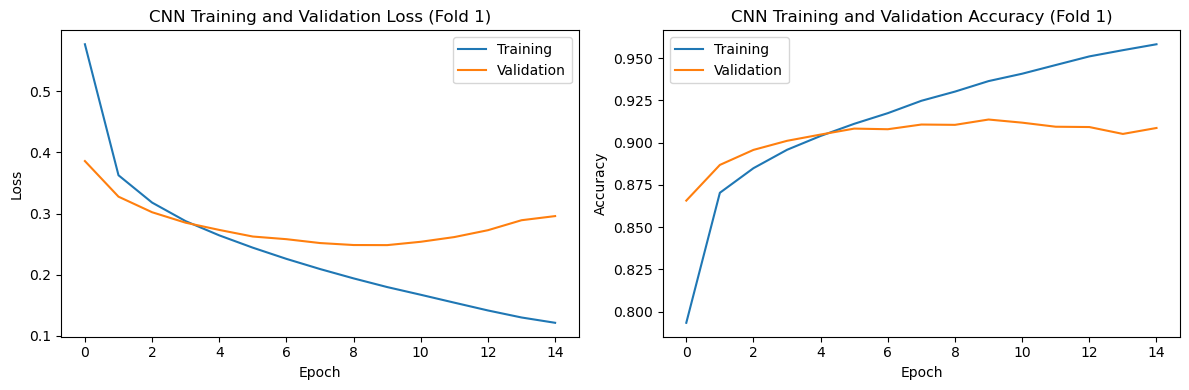

In [22]:
# CNN training history (Fold 1)
history = cnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history['loss'], label='Training')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('CNN Training and Validation Loss (Fold 1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history['accuracy'], label='Training')
axes[1].plot(history['val_accuracy'], label='Validation')
axes[1].set_title('CNN Training and Validation Accuracy (Fold 1)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 1.6.4. CNN Optimization

기본 CNN의 학습 곡선에서 과적합 징후가 관찰되어 완전연결 은닉층 뒤에 Dropout(0.25)을 적용하였다. 기존 모델의 구조와 학습 조건을 유지한 상태에서 동일한 10-Fold 교차검증으로 성능 변화를 평가하였다.

In [23]:
# Optimized CNN model
def build_optimized_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),

        tf.keras.layers.Conv2D(
            32, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            64, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

optimized_cnn = build_optimized_cnn()
optimized_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Optimized CNN: 10-Fold Cross-Validation
optimized_cnn_cv_results = []
optimized_cnn_histories = []

for fold, (train_idx, val_idx) in enumerate(fold_indices, start=1):
    print(f"\n===== Optimized CNN: Fold {fold}/10 =====")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = x_train_cnn[train_idx]
    y_fold_train = y_train[train_idx]

    x_fold_val = x_train_cnn[val_idx]
    y_fold_val = y_train[val_idx]

    # Internal validation set for Early Stopping
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_optimized_cnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate on held-out CV fold
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    optimized_cnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    optimized_cnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")


===== Optimized CNN: Fold 1/10 =====
Validation Accuracy: 0.9110
Validation Loss: 0.2364

===== Optimized CNN: Fold 2/10 =====
Validation Accuracy: 0.9123
Validation Loss: 0.2634

===== Optimized CNN: Fold 3/10 =====
Validation Accuracy: 0.9087
Validation Loss: 0.2522

===== Optimized CNN: Fold 4/10 =====
Validation Accuracy: 0.9192
Validation Loss: 0.2309

===== Optimized CNN: Fold 5/10 =====
Validation Accuracy: 0.9118
Validation Loss: 0.2537

===== Optimized CNN: Fold 6/10 =====
Validation Accuracy: 0.9122
Validation Loss: 0.2535

===== Optimized CNN: Fold 7/10 =====
Validation Accuracy: 0.9172
Validation Loss: 0.2351

===== Optimized CNN: Fold 8/10 =====
Validation Accuracy: 0.9065
Validation Loss: 0.2533

===== Optimized CNN: Fold 9/10 =====
Validation Accuracy: 0.9107
Validation Loss: 0.2315

===== Optimized CNN: Fold 10/10 =====
Validation Accuracy: 0.9162
Validation Loss: 0.2408


#### 1.6.5. CNN Model Comparison

In [25]:
# Optimized CNN results
optimized_cnn_cv_df = pd.DataFrame(optimized_cnn_cv_results)

print("=== Optimized CNN 10-Fold Results ===")
print(optimized_cnn_cv_df.round(4).to_string(index=False))

# Model comparison
cnn_comparison = pd.DataFrame({
    'Model': ['Baseline CNN', 'Optimized CNN'],
    'Mean Accuracy': [
        cnn_cv_df['Accuracy'].mean(),
        optimized_cnn_cv_df['Accuracy'].mean()
    ],
    'Std Accuracy': [
        cnn_cv_df['Accuracy'].std(),
        optimized_cnn_cv_df['Accuracy'].std()
    ],
    'Mean Loss': [
        cnn_cv_df['Loss'].mean(),
        optimized_cnn_cv_df['Loss'].mean()
    ],
    'Std Loss': [
        cnn_cv_df['Loss'].std(),
        optimized_cnn_cv_df['Loss'].std()
    ]
})

print("\n=== CNN Model Comparison ===")
print(cnn_comparison.round(4).to_string(index=False))

=== Optimized CNN 10-Fold Results ===
 Fold   Loss  Accuracy  Epochs
    1 0.2364    0.9110      15
    2 0.2634    0.9123      20
    3 0.2522    0.9087      18
    4 0.2309    0.9192      18
    5 0.2537    0.9118      20
    6 0.2535    0.9122      19
    7 0.2351    0.9172      17
    8 0.2533    0.9065      15
    9 0.2315    0.9107      16
   10 0.2408    0.9162      17

=== CNN Model Comparison ===
        Model  Mean Accuracy  Std Accuracy  Mean Loss  Std Loss
 Baseline CNN         0.9077        0.0038     0.2598    0.0110
Optimized CNN         0.9126        0.0039     0.2451    0.0114


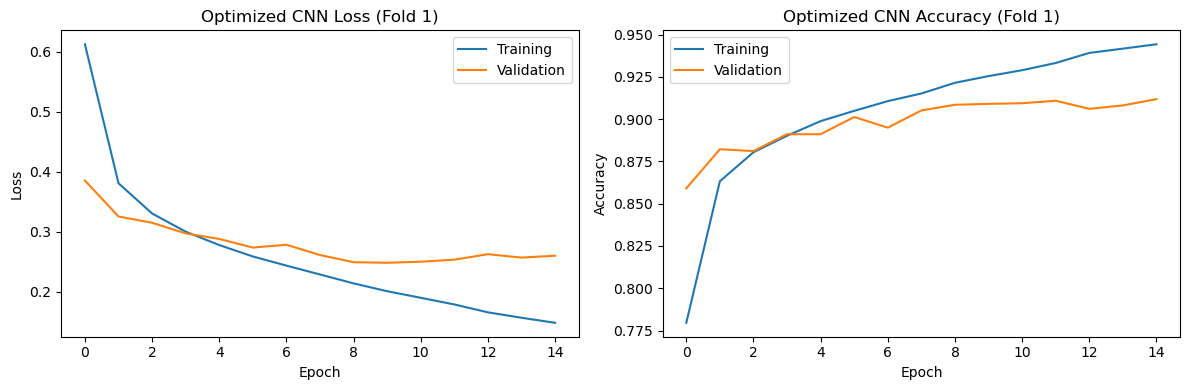

In [26]:
# Optimized CNN training history (Fold 1)
history = optimized_cnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history['loss'], label='Training')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('Optimized CNN Loss (Fold 1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history['accuracy'], label='Training')
axes[1].plot(history['val_accuracy'], label='Validation')
axes[1].set_title('Optimized CNN Accuracy (Fold 1)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 1.6.6. CNN Optimization Results

Stratified 10-Fold 교차검증 결과, Dropout(0.25)을 적용한 CNN의 평균 정확도는 91.26%로 기본 CNN(90.77%)보다 0.49%p 높게 나타났다. 평균 손실도 0.2598에서 0.2451로 감소하였으며, 10개 Fold 중 8개에서 정확도가 개선되었다.

Fold 간 성능 변동은 두 모델에서 유사하게 나타났고, 학습 곡선에서는 여전히 일부 과적합 징후가 관찰되었다. 따라서 과적합이 완전히 해소되었다고 볼 수는 없지만 동일한 파라미터 수에서 상대적으로 우수한 분류 성능을 보인 Dropout CNN을 최종 모델 후보로 선정하였다.

#### 1.6.7. Final CNN Evaluation

In [27]:
# Select final training epochs from CNN cross-validation
cnn_best_epochs = [
    int(np.argmin(history['val_loss']) + 1)
    for history in optimized_cnn_histories
]

cnn_final_epochs = int(np.median(cnn_best_epochs))

print("Best Epochs:", cnn_best_epochs)
print("Selected Epochs:", cnn_final_epochs)

# Final CNN training
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

final_cnn = build_optimized_cnn()

final_cnn_history = final_cnn.fit(
    x_train_cnn,
    y_train,
    epochs=cnn_final_epochs,
    batch_size=BATCH_SIZE,
    verbose=1
)

Best Epochs: [10, 15, 13, 13, 15, 14, 12, 10, 11, 12]
Selected Epochs: 12
Epoch 1/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.7890 - loss: 0.5840
Epoch 2/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8679 - loss: 0.3678
Epoch 3/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8839 - loss: 0.3173
Epoch 4/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.8951 - loss: 0.2867
Epoch 5/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9040 - loss: 0.2639
Epoch 6/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9093 - loss: 0.2444
Epoch 7/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9151 - loss: 0.2278
Epoch 8/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.9205 - loss: 0.2129
Epoch 9/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9269 - loss: 0.1984
Epoch 10/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.9306 - loss: 0.1868
Epoch 11/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 

In [28]:
# Final CNN test evaluation
y_prob_cnn = final_cnn.predict(x_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)

cnn_test_loss, cnn_test_accuracy = final_cnn.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print("=== Final CNN Test Results ===")
print(f"Test Accuracy: {cnn_test_accuracy:.4f}")
print(f"Test Loss    : {cnn_test_loss:.4f}")

print("\n=== Classification Report ===")
print(
    classification_report(
        y_test,
        y_pred_cnn,
        target_names=class_names,
        digits=4
    )
)

=== Final CNN Test Results ===
Test Accuracy: 0.9077
Test Loss    : 0.2619

=== Classification Report ===
              precision    recall  f1-score   support

 T-shirt/top     0.8374    0.8600    0.8485      1000
     Trouser     0.9929    0.9800    0.9864      1000
    Pullover     0.8103    0.8930    0.8497      1000
       Dress     0.9187    0.9150    0.9168      1000
        Coat     0.8913    0.8120    0.8498      1000
      Sandal     0.9869    0.9790    0.9829      1000
       Shirt     0.7544    0.7370    0.7456      1000
     Sneaker     0.9303    0.9880    0.9583      1000
         Bag     0.9809    0.9770    0.9790      1000
  Ankle boot     0.9853    0.9360    0.9600      1000

    accuracy                         0.9077     10000
   macro avg     0.9088    0.9077    0.9077     10000
weighted avg     0.9088    0.9077    0.9077     10000



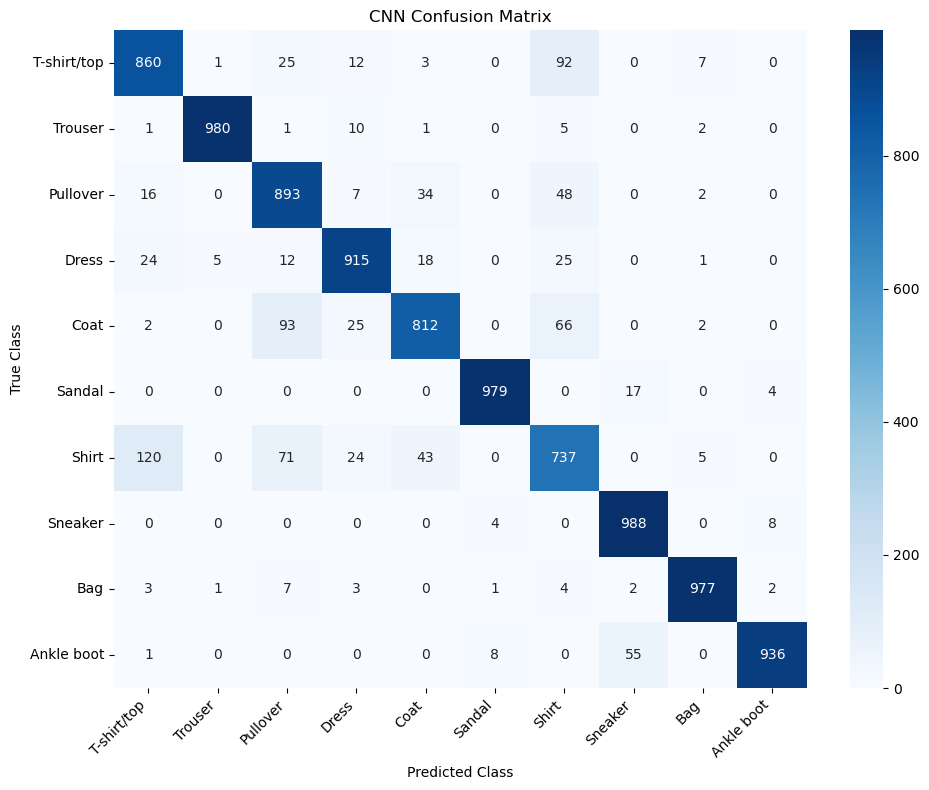

In [29]:
# CNN confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_cnn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
# Save final CNN results
cnn_final_results = {
    'Model': 'CNN',
    'Accuracy': accuracy_score(y_test, y_pred_cnn),
    'Precision': precision_score(
        y_test, y_pred_cnn, average='macro'
    ),
    'Recall': recall_score(
        y_test, y_pred_cnn, average='macro'
    ),
    'F1-score': f1_score(
        y_test, y_pred_cnn, average='macro'
    ),
    'Parameters': final_cnn.count_params()
}

#### 1.6.8. Final CNN Results

Dropout(0.25)을 적용한 CNN의 최종 테스트 정확도는 90.77%, Macro F1-score는 90.77%로 나타났다. 이는 10-Fold 교차검증 평균 정확도(91.26%)와 유사한 수준으로, 교차검증에서 확인한 성능이 테스트 데이터에서도 대체로 유지되었다.

클래스별 성능 분석에서는 Trouser, Sandal, Bag 등이 높은 분류 성능을 보인 반면, Shirt는 상대적으로 낮은 F1-score를 기록하였다. 혼동행렬에서도 형태가 유사한 상의 클래스 간 오분류가 관찰되었으나, DNN과 비교하면 Shirt, Pullover, Coat의 F1-score가 개선되었다.

### 1.7. DNN vs CNN Comparison

In [31]:
# Overall performance comparison
model_comparison = pd.DataFrame([
    dnn_final_results,
    cnn_final_results
]).set_index('Model')

model_comparison['Loss'] = [test_loss, cnn_test_loss]

model_comparison = model_comparison[
    ['Accuracy', 'Precision', 'Recall',
     'F1-score', 'Loss', 'Parameters']
]

print("=== DNN vs CNN: Test Performance ===")
print(model_comparison.round(4).to_string())

=== DNN vs CNN: Test Performance ===
       Accuracy  Precision  Recall  F1-score    Loss  Parameters
Model                                                           
DNN      0.8843     0.8853  0.8843    0.8845  0.3299      235146
CNN      0.9077     0.9088  0.9077    0.9077  0.2619      225034


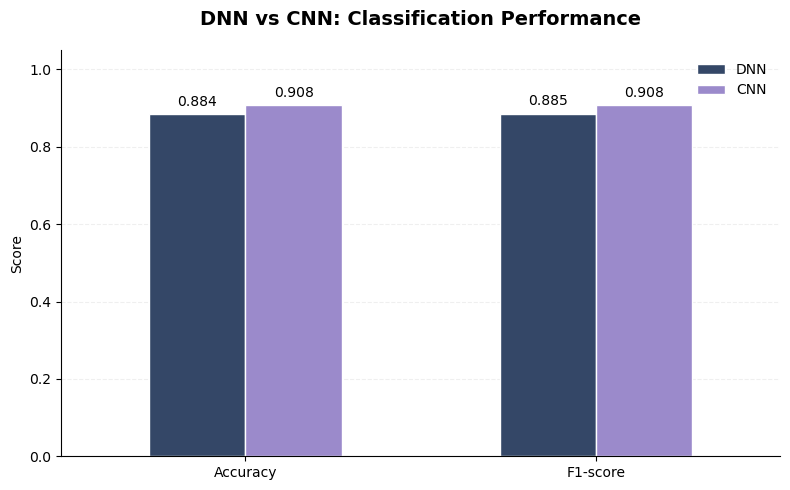

In [32]:
# Overall classification performance
metrics_df = model_comparison[
    ['Accuracy', 'F1-score']
].T

colors = ['#344767', '#9B8ACB']

fig, ax = plt.subplots(figsize=(8, 5))

metrics_df.plot(
    kind='bar',
    ax=ax,
    color=colors,
    width=0.55,
    rot=0,
    edgecolor='white'
)

ax.set_title(
    'DNN vs CNN: Classification Performance',
    fontsize=14,
    fontweight='bold',
    pad=18
)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)

ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

ax.legend(title=None, frameon=False)

# Value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

#### 1.7.1. Class-wise Performance Comparison

In [33]:
# Class-wise F1-scores
dnn_f1 = f1_score(
    y_test, y_pred_dnn, average=None
)

cnn_f1 = f1_score(
    y_test, y_pred_cnn, average=None
)

class_f1_comparison = pd.DataFrame({
    'Class': class_names,
    'DNN': dnn_f1,
    'CNN': cnn_f1
})

class_f1_comparison['Difference'] = (
    class_f1_comparison['CNN']
    - class_f1_comparison['DNN']
)

print("=== Class-wise F1-score Comparison ===")
print(class_f1_comparison.round(4).to_string(index=False))

=== Class-wise F1-score Comparison ===
      Class    DNN    CNN  Difference
T-shirt/top 0.8452 0.8485      0.0033
    Trouser 0.9789 0.9864      0.0075
   Pullover 0.7861 0.8497      0.0636
      Dress 0.8942 0.9168      0.0226
       Coat 0.8080 0.8498      0.0418
     Sandal 0.9653 0.9829      0.0177
      Shirt 0.6942 0.7456      0.0514
    Sneaker 0.9466 0.9583      0.0117
        Bag 0.9739 0.9790      0.0050
 Ankle boot 0.9530 0.9600      0.0070


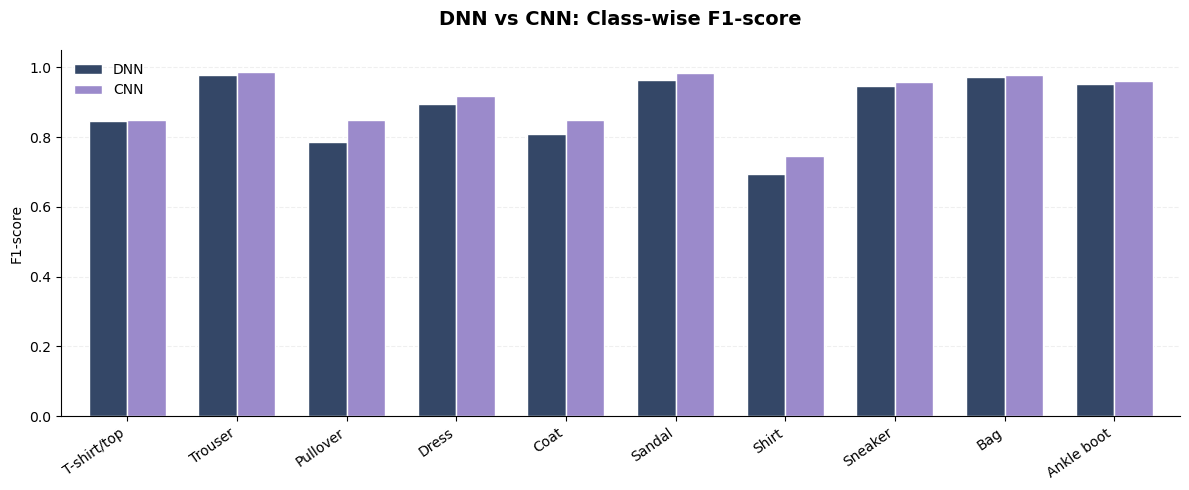

In [34]:
# Class-wise F1-score comparison
fig, ax = plt.subplots(figsize=(12, 5))

class_f1_comparison.set_index('Class')[
    ['DNN', 'CNN']
].plot(
    kind='bar',
    ax=ax,
    color=colors,
    width=0.7,
    rot=45,
    edgecolor='white'
)

ax.set_title(
    'DNN vs CNN: Class-wise F1-score',
    fontsize=14,
    fontweight='bold',
    pad=18
)
ax.set_xlabel('')
ax.set_ylabel('F1-score')
ax.set_ylim(0, 1.05)

ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

ax.legend(title=None, frameon=False)

plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

#### 1.7.2. Comparison Results

최종 테스트 결과, CNN의 정확도는 90.77%로 DNN(88.43%)보다 2.34%p 높았으며, Macro F1-score 역시 CNN이 더 높게 나타났다. CNN은 DNN보다 파라미터 수가 적음에도 우수한 분류 성능을 보였다.

클래스별 비교에서는 CNN이 Shirt, Pullover, Coat 등 형태가 유사한 일부 상의 클래스의 F1-score를 개선하였다. 이는 CNN이 합성곱 연산을 통해 이미지의 국소적 특징과 공간적 구조를 효과적으로 학습했기 때문으로 해석할 수 있다.

따라서 이번 Fashion-MNIST 실험에서는 입력 이미지를 평탄화하여 처리하는 DNN보다 공간적 정보를 활용하는 CNN이 더 높은 분류 성능을 보였다.

### 1.8. Parameter Calculation

#### 1.8.1. Parameter Calculation Formulas

**Dense Layer**

완전연결 계층의 파라미터는 입력 뉴런과 출력 뉴런을 연결하는 가중치와 출력 뉴런별 편향으로 구성된다.

$$
P_{\text{Dense}}=(N_{\text{input}}\times N_{\text{output}})+N_{\text{output}}
$$

**Conv2D Layer**

합성곱 계층의 파라미터는 커널 크기, 입력 채널 수, 필터 수 및 편향에 의해 결정된다.

$$
P_{\text{Conv2D}}=(K_h\times K_w\times C_{\text{in}}+1)\times C_{\text{out}}
$$

MaxPooling, Flatten, Dropout 계층에는 학습 가능한 가중치와 편향이 없으므로 파라미터 수는 0이다.

#### 1.8.2. DNN Parameter Calculation

| Layer | Calculation | Parameters |
|---|---|---:|
| Dense (256) | 784 × 256 + 256 | 200,960 |
| Dense (128) | 256 × 128 + 128 | 32,896 |
| Dropout (0.25) | No trainable parameters | 0 |
| Dense (10) | 128 × 10 + 10 | 1,290 |
| **Total** | | **235,146** |

따라서 DNN의 전체 파라미터 수는 다음과 같다.

$$
P_{\text{DNN}}=200,960+32,896+1,290=\boxed{235,146}
$$

Dropout은 학습 과정에서 일부 뉴런의 출력을 비활성화하지만, 별도의 학습 가능한 파라미터를 추가하지 않는다.

#### 1.8.3. CNN Parameter Calculation

| Layer | Output Shape | Calculation | Parameters |
|---|---|---|---:|
| Conv2D (32) | 26 × 26 × 32 | (3 × 3 × 1 + 1) × 32 | 320 |
| MaxPooling2D | 13 × 13 × 32 | No trainable parameters | 0 |
| Conv2D (64) | 11 × 11 × 64 | (3 × 3 × 32 + 1) × 64 | 18,496 |
| MaxPooling2D | 5 × 5 × 64 | No trainable parameters | 0 |
| Flatten | 1,600 | No trainable parameters | 0 |
| Dense (128) | 128 | 1,600 × 128 + 128 | 204,928 |
| Dropout (0.25) | 128 | No trainable parameters | 0 |
| Dense (10) | 10 | 128 × 10 + 10 | 1,290 |
| **Total** | | | **225,034** |

따라서 CNN의 전체 파라미터 수는 다음과 같다.

$$
P_{\text{CNN}}=320+18,496+204,928+1,290=\boxed{225,034}
$$

CNN에서는 합성곱 필터의 가중치를 이미지의 여러 위치에서 공유하므로, 각 공간 위치마다 별도의 파라미터를 학습하지 않는다. 또한 Flatten 계층은 특징맵의 형태만 변경하며 새로운 파라미터를 생성하지 않는다.

In [35]:
# Parameter count verification
parameter_comparison = pd.DataFrame({
    'Model': ['DNN', 'CNN'],
    'Calculated Parameters': [235146, 225034],
    'Keras Parameters': [
        final_dnn.count_params(),
        final_cnn.count_params()
    ]
})

parameter_comparison['Match'] = (
    parameter_comparison['Calculated Parameters']
    == parameter_comparison['Keras Parameters']
)

print("=== Parameter Count Verification ===")
print(parameter_comparison.to_string(index=False))

=== Parameter Count Verification ===
Model  Calculated Parameters  Keras Parameters  Match
  DNN                 235146            235146   True
  CNN                 225034            225034   True


#### 1.8.4. Parameter Comparison Results

DNN의 전체 파라미터 수는 235,146개, CNN은 225,034개로 CNN이 10,112개 적었다. 두 모델 모두 직접 계산한 파라미터 수가 Keras의 출력 결과와 일치하였다.

CNN은 합성곱 계층에서 가중치를 공유하여 이미지의 공간적 특징을 추출하며, 이번 실험에서는 DNN보다 적은 파라미터로 높은 분류 정확도를 달성하였다.

### 1.9. Conclusion

Fashion-MNIST 분류를 위해 DNN과 CNN을 학습하고 Stratified 10-Fold 교차검증과 최종 테스트 데이터를 이용하여 성능을 평가하였다.

최종 테스트 정확도는 DNN 88.43%, CNN 90.77%로 CNN이 2.34%p 높았다. 특히 CNN은 형태가 유사한 일부 의류 클래스에서 DNN보다 높은 분류 성능을 보였다.

전체 파라미터 수는 DNN 235,146개, CNN 225,034개로 계산되었다. 따라서 이번 실험에서는 CNN이 더 적은 파라미터를 사용하면서도 높은 분류 정확도를 달성하였다.

이는 이미지의 국소적 특징과 공간적 구조를 활용하는 합성곱 신경망의 장점과 일치한다.

## 2. CIFAR-10

### 2.1. Data Loading

In [36]:
from tensorflow.keras.datasets import cifar10

# Load dataset
(cifar_x_train, cifar_y_train), (cifar_x_test, cifar_y_test) = cifar10.load_data()

# Reshape labels
cifar_y_train = cifar_y_train.ravel()
cifar_y_test = cifar_y_test.ravel()

# Class names
cifar_class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

### 2.2. Exploratory Data Analysis (EDA)

#### 2.2.1. Dataset Overview

In [37]:
# Dataset information
print("=== Dataset Information ===")
print(f"Training images: {cifar_x_train.shape}")
print(f"Test images: {cifar_x_test.shape}")
print(f"Data type: {cifar_x_train.dtype}")

# Pixel range
print("\n=== Pixel Value Range ===")
print(f"Minimum: {cifar_x_train.min()}")
print(f"Maximum: {cifar_x_train.max()}")

# Missing values
print("\n=== Missing Values ===")
print(f"Training: {np.isnan(cifar_x_train).sum()}")
print(f"Test: {np.isnan(cifar_x_test).sum()}")

# Number of classes
print("\n=== Number of Classes ===")
print(len(np.unique(cifar_y_train)))

=== Dataset Information ===
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)
Data type: uint8

=== Pixel Value Range ===
Minimum: 0
Maximum: 255

=== Missing Values ===
Training: 0
Test: 0

=== Number of Classes ===
10


#### 2.2.2. Class Distribution

In [38]:
# Class distribution
cifar_class_distribution = pd.DataFrame({
    'Class': cifar_class_names,
    'Train Count': np.bincount(cifar_y_train, minlength=10),
    'Test Count': np.bincount(cifar_y_test, minlength=10)
})

print("=== Class Distribution ===")
print(cifar_class_distribution.to_string(index=False))

=== Class Distribution ===
     Class  Train Count  Test Count
  Airplane         5000        1000
Automobile         5000        1000
      Bird         5000        1000
       Cat         5000        1000
      Deer         5000        1000
       Dog         5000        1000
      Frog         5000        1000
     Horse         5000        1000
      Ship         5000        1000
     Truck         5000        1000


#### 2.2.3. Sample Visualization

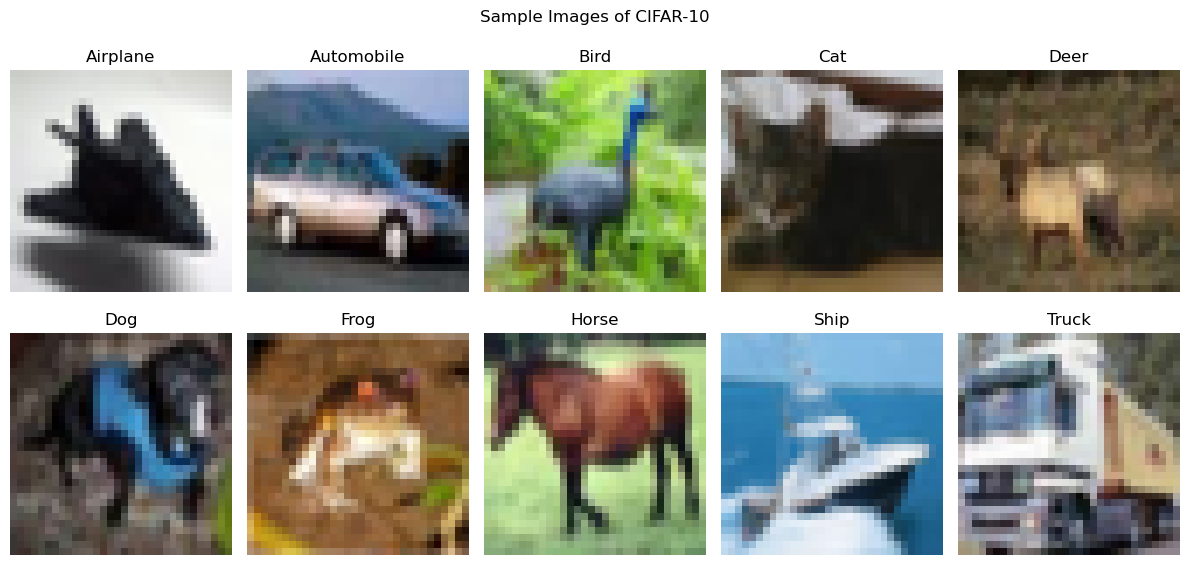

In [39]:
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    idx = np.where(cifar_y_train == i)[0][0]

    ax.imshow(cifar_x_train[idx])
    ax.set_title(cifar_class_names[i])
    ax.axis('off')

plt.suptitle('Sample Images of CIFAR-10')
plt.tight_layout()
plt.show()

#### 2.2.4. EDA Results

CIFAR-10은 클래스별 데이터가 균등하게 분포하여 별도의 클래스 불균형 보정이 필요하지 않다. 

이미지에는 객체뿐 아니라 다양한 배경과 색상 정보가 포함되어 있으며, 낮은 해상도로 인해 일부 객체의 세부 특징을 구분하기 어렵다. 따라서 모델 학습 후 클래스별 분류 성능과 오분류 양상을 함께 분석할 필요가 있다.

### 2.3. Data Preprocessing

픽셀값을 0~1 범위로 정규화하고, 모델의 입력 구조에 맞게 데이터를 변환한다. DNN은 이미지를 3,072차원 벡터로 변환하며, CNN은 RGB 이미지의 공간적 특징을 학습할 수 있도록 32×32×3 형태를 유지한다.

In [40]:
# Data normalization
cifar_x_train_norm = cifar_x_train.astype('float32') / 255.0
cifar_x_test_norm = cifar_x_test.astype('float32') / 255.0

# DNN input
cifar_x_train_dnn = cifar_x_train_norm.reshape(-1, 3072)
cifar_x_test_dnn = cifar_x_test_norm.reshape(-1, 3072)

# CNN input
cifar_x_train_cnn = cifar_x_train_norm
cifar_x_test_cnn = cifar_x_test_norm

### 2.4. Cross-Validation Strategy

In [41]:
# Stratified 10-Fold Cross-Validation
cifar_skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cifar_fold_indices = list(
    cifar_skf.split(cifar_x_train_dnn, cifar_y_train)
)

### 2.5. DNN Model

#### 2.5.1. Model Architecture

CIFAR-10 이미지 분류를 위해 Batch Normalization과 Residual Connection을 적용한 DNN(Residual MLP)을 구성하였다. 두 개의 Residual Block을 통해 특징을 학습하고, Dropout을 적용하여 과적합을 완화하도록 설계하였다.

은닉층 크기, 학습률, Dropout 비율 등은 일반적인 신경망 학습 설정과 계산 비용을 고려한 초기값으로 지정하였으며, 모델의 성능은 Stratified 10-Fold 교차검증을 통해 평가하였다.

In [42]:
# Residual block for DNN
def dnn_residual_block(x, units=256):
    shortcut = x

    x = tf.keras.layers.Dense(units, use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    x = tf.keras.layers.Dense(units, use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation('relu')(x)

    return x

# Residual DNN model
def build_cifar_dnn():
    inputs = tf.keras.layers.Input(shape=(3072,))

    x = tf.keras.layers.Dense(256, use_bias=False)(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    x = dnn_residual_block(x, units=256)
    x = dnn_residual_block(x, units=256)

    x = tf.keras.layers.Dropout(0.2)(x)

    outputs = tf.keras.layers.Dense(
        10, activation='softmax'
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='CIFAR10_Residual_DNN'
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Model architecture
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

cifar_dnn = build_cifar_dnn()
cifar_dnn.summary()

Model: "CIFAR10_Residual_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 3072)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         786,432 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 256)               │           1,024 │ dense[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 256)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 256)               │          65,536 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense_1[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 256)               │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 256)               │          65,536 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 256)               │           1,024 │ dense_2[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 256)               │               0 │ batch_normalization_2[0][… │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 256)               │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 256)               │          65,536 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 256)               │           1,024 │ dense_3[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 256)               │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 256)               │          65,53

 Total params: 1,056,266 (4.03 MB)

 Trainable params: 1,053,706 (4.02 MB)

 Non-trainable params: 2,560 (10.00 KB)

#### 2.5.2. Model Training and Cross-Validation

In [43]:
# Training settings
CIFAR_EPOCHS = 30
CIFAR_BATCH_SIZE = 128

# Cross-validation results
cifar_dnn_cv_results = []
cifar_dnn_histories = []

for fold, (train_idx, val_idx) in enumerate(
    cifar_fold_indices, start=1
):
    print(f"\n===== CIFAR-10 DNN: Fold {fold}/10 =====")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = cifar_x_train_dnn[train_idx]
    y_fold_train = cifar_y_train[train_idx]

    x_fold_val = cifar_x_train_dnn[val_idx]
    y_fold_val = cifar_y_train[val_idx]

    # Internal validation set for Early Stopping
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_cifar_dnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Training
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=CIFAR_EPOCHS,
        batch_size=CIFAR_BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Fold evaluation
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    cifar_dnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    cifar_dnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")


===== CIFAR-10 DNN: Fold 1/10 =====
Validation Accuracy: 0.4190
Validation Loss: 1.6806

===== CIFAR-10 DNN: Fold 2/10 =====
Validation Accuracy: 0.3766
Validation Loss: 1.8321

===== CIFAR-10 DNN: Fold 3/10 =====
Validation Accuracy: 0.4258
Validation Loss: 1.7433

===== CIFAR-10 DNN: Fold 4/10 =====
Validation Accuracy: 0.3904
Validation Loss: 1.7245

===== CIFAR-10 DNN: Fold 5/10 =====
Validation Accuracy: 0.4130
Validation Loss: 1.7130

===== CIFAR-10 DNN: Fold 6/10 =====
Validation Accuracy: 0.3794
Validation Loss: 1.8222

===== CIFAR-10 DNN: Fold 7/10 =====
Validation Accuracy: 0.3910
Validation Loss: 1.7457

===== CIFAR-10 DNN: Fold 8/10 =====
Validation Accuracy: 0.3604
Validation Loss: 1.8239

===== CIFAR-10 DNN: Fold 9/10 =====
Validation Accuracy: 0.4034
Validation Loss: 1.7412

===== CIFAR-10 DNN: Fold 10/10 =====
Validation Accuracy: 0.3150
Validation Loss: 2.1428


#### 2.5.3. Cross-Validation Results

In [44]:
# CIFAR-10 DNN cross-validation results
cifar_dnn_cv_df = pd.DataFrame(cifar_dnn_cv_results)

print("=== CIFAR-10 DNN 10-Fold Results ===")
print(cifar_dnn_cv_df.round(4).to_string(index=False))

print("\n=== Summary ===")
print(f"Mean Accuracy: {cifar_dnn_cv_df['Accuracy'].mean():.4f}")
print(f"Std Accuracy : {cifar_dnn_cv_df['Accuracy'].std():.4f}")
print(f"Mean Loss    : {cifar_dnn_cv_df['Loss'].mean():.4f}")
print(f"Std Loss     : {cifar_dnn_cv_df['Loss'].std():.4f}")

=== CIFAR-10 DNN 10-Fold Results ===
 Fold   Loss  Accuracy  Epochs
    1 1.6806    0.4190       9
    2 1.8321    0.3766      10
    3 1.7433    0.4258      12
    4 1.7245    0.3904       8
    5 1.7130    0.4130       8
    6 1.8222    0.3794       8
    7 1.7457    0.3910       9
    8 1.8239    0.3604       8
    9 1.7412    0.4034       8
   10 2.1428    0.3150       8

=== Summary ===
Mean Accuracy: 0.3874
Std Accuracy : 0.0326
Mean Loss    : 1.7969
Std Loss     : 0.1319


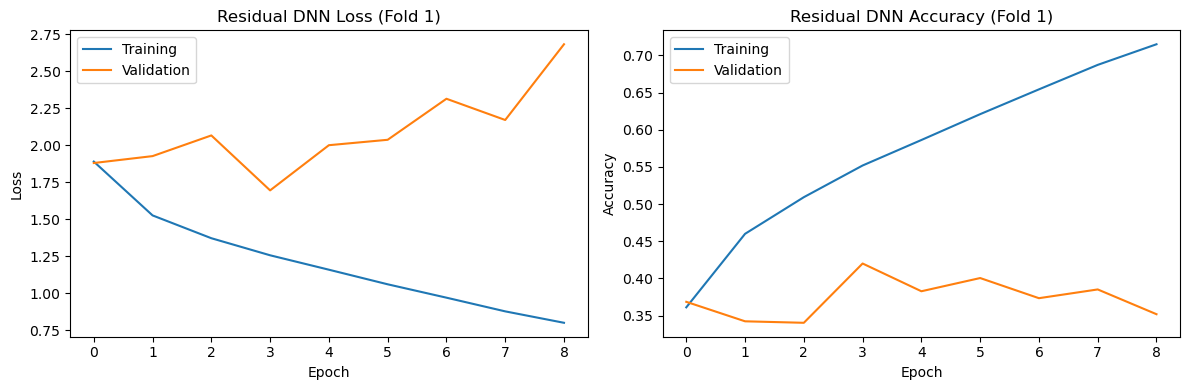

In [45]:
# DNN training history (Fold 1)
history = cifar_dnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(
        history[metric],
        label='Training'
    )
    ax.plot(
        history[f'val_{metric}'],
        label='Validation'
    )

    ax.set_title(f'Residual DNN {metric.title()} (Fold 1)')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.title())
    ax.legend()

plt.tight_layout()
plt.show()

#### 2.5.4. DNN Cross-Validation Results Interpretation

Stratified 10-Fold 교차검증 결과, Residual DNN의 평균 정확도는 38.74%, 평균 손실은 1.7969로 나타났다.

첫 번째 Fold의 학습 곡선에서는 훈련 정확도가 지속적으로 증가한 반면 검증 정확도는 낮은 수준에서 정체되었으며, 훈련 손실과 검증 손실의 차이도 확대되었다. 이는 현재 DNN이 훈련 데이터의 특징을 학습하였으나 검증 데이터에 대한 일반화 성능은 제한적임을 보여준다.

이후 CNN과의 비교를 통해 이미지의 공간적 구조를 활용하는 모델의 분류 성능을 분석한다.

### 2.6. CNN Model

#### 2.6.1. Model Architecture

CIFAR-10 이미지 분류를 위해 Batch Normalization과 Residual Connection을 적용한 ResNet 기반 CNN을 구성하였다. 각 Residual Block은 Conv2D 계층과 Shortcut Connection으로 구성되며, 입력과 출력의 차원이 달라지는 경우 1×1 합성곱을 이용해 차원을 조정한다.

모델은 16, 32, 64개의 필터를 사용하는 세 개의 Residual Block과 Global Average Pooling으로 구성하였다. 이는 ResNet의 잔차 학습 원리를 활용하되, CIFAR-10 이미지 크기와 학습 비용을 고려해 경량화한 구조이다.

In [46]:
# Residual block for CNN
def cifar_cnn_residual_block(x, filters, stride=1):
    shortcut = x

    x = tf.keras.layers.Conv2D(
        filters, (3, 3),
        strides=stride,
        padding='same',
        use_bias=False
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    x = tf.keras.layers.Conv2D(
        filters, (3, 3),
        padding='same',
        use_bias=False
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)

    # Projection shortcut
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, (1, 1),
            strides=stride,
            padding='same',
            use_bias=False
        )(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)

    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation('relu')(x)

    return x


# ResNet-based CNN
def build_cifar_cnn():
    inputs = tf.keras.Input(shape=(32, 32, 3))

    x = tf.keras.layers.Conv2D(
        16, (3, 3),
        padding='same',
        use_bias=False
    )(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    x = cifar_cnn_residual_block(x, filters=16)
    x = cifar_cnn_residual_block(x, filters=32, stride=2)
    x = cifar_cnn_residual_block(x, filters=64, stride=2)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    outputs = tf.keras.layers.Dense(
        10, activation='softmax'
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='CIFAR10_Residual_CNN'
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# Model architecture
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

cifar_cnn = build_cifar_cnn()
cifar_cnn.summary()

Model: "CIFAR10_Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 16)        │             432 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 16)        │              64 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 16)        │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 32, 32, 16)        │           2,304 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 32, 32, 16)        │              64 │ conv2d_1[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 32, 32, 16)        │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 32, 32, 16)        │           2,304 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 32, 32, 16)        │              64 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 32, 32, 16)        │               0 │ batch_normalization_2[0][… │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 32, 32, 16)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 32)        │           4,608 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 16, 16, 32)        │             128 │ conv2d_3[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 16, 16, 32)        │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 16, 16, 32)        │           9,21

 Total params: 78,714 (307.48 KB)

 Trainable params: 78,042 (304.85 KB)

 Non-trainable params: 672 (2.62 KB)

#### 2.6.2. Model Training and Cross-Validation

In [47]:
import os
import pickle

# Training settings
CIFAR_EPOCHS = 30
CIFAR_BATCH_SIZE = 128

# Saved progress file
progress_path = 'cifar_cnn_cv_progress.pkl'

if not os.path.exists(progress_path):
    raise FileNotFoundError(
        f"저장 파일을 찾을 수 없습니다.: {os.path.abspath(progress_path)}"
    )

# Load completed folds
with open(progress_path, 'rb') as f:
    progress = pickle.load(f)

cifar_cnn_cv_results = progress['results']
cifar_cnn_histories = progress['histories']

completed_folds = {
    int(result['Fold'])
    for result in cifar_cnn_cv_results
}

if len(cifar_cnn_cv_results) != len(cifar_cnn_histories):
    raise ValueError("저장된 결과 수와 학습 기록 수가 다릅니다.")

print("Completed Folds:", sorted(completed_folds))
print(
    "Remaining Folds:",
    sorted(set(range(1, 11)) - completed_folds)
)

# Resume CNN Cross-Validation
for fold, (train_idx, val_idx) in enumerate(
    cifar_fold_indices, start=1
):
    if fold in completed_folds:
        print(f"Fold {fold}/10: Skipped (Already completed)")
        continue

    print(f"\n===== CIFAR-10 CNN: Fold {fold}/10 =====")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    # Cross-validation split
    x_fold_train = cifar_x_train_cnn[train_idx]
    y_fold_train = cifar_y_train[train_idx]

    x_fold_val = cifar_x_train_cnn[val_idx]
    y_fold_val = cifar_y_train[val_idx]

    # Internal validation set
    x_fit, x_es, y_fit, y_es = train_test_split(
        x_fold_train,
        y_fold_train,
        test_size=0.1,
        stratify=y_fold_train,
        random_state=42
    )

    # Build model
    model = build_cifar_cnn()

    # Early Stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Model training
    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_es, y_es),
        epochs=CIFAR_EPOCHS,
        batch_size=CIFAR_BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0
    )

    # Fold evaluation
    val_loss, val_accuracy = model.evaluate(
        x_fold_val,
        y_fold_val,
        verbose=0
    )

    cifar_cnn_cv_results.append({
        'Fold': fold,
        'Loss': val_loss,
        'Accuracy': val_accuracy,
        'Epochs': len(history.history['loss'])
    })

    cifar_cnn_histories.append(history.history)

    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    # Save after each completed fold
    temp_path = progress_path + '.tmp'

    with open(temp_path, 'wb') as f:
        pickle.dump({
            'results': cifar_cnn_cv_results,
            'histories': cifar_cnn_histories
        }, f)

    os.replace(temp_path, progress_path)

    completed_folds.add(fold)

    print(f"Progress Saved: {len(completed_folds)}/10 Folds")

print("\n===== CNN Cross-Validation Status =====")
print(f"Completed: {len(completed_folds)}/10 Folds")

Completed Folds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Remaining Folds: []
Fold 1/10: Skipped (Already completed)
Fold 2/10: Skipped (Already completed)
Fold 3/10: Skipped (Already completed)
Fold 4/10: Skipped (Already completed)
Fold 5/10: Skipped (Already completed)
Fold 6/10: Skipped (Already completed)
Fold 7/10: Skipped (Already completed)
Fold 8/10: Skipped (Already completed)
Fold 9/10: Skipped (Already completed)
Fold 10/10: Skipped (Already completed)

===== CNN Cross-Validation Status =====
Completed: 10/10 Folds


#### 2.6.3. Cross-Validation Results

In [48]:
# CNN cross-validation results
cifar_cnn_cv_df = (
    pd.DataFrame(cifar_cnn_cv_results)
    .sort_values('Fold')
    .reset_index(drop=True)
)

print("=== CIFAR-10 CNN 10-Fold Results ===")
print(cifar_cnn_cv_df.round(4).to_string(index=False))

print("\n=== Summary ===")
print(f"Mean Accuracy: {cifar_cnn_cv_df['Accuracy'].mean():.4f}")
print(f"Std Accuracy : {cifar_cnn_cv_df['Accuracy'].std():.4f}")
print(f"Mean Loss    : {cifar_cnn_cv_df['Loss'].mean():.4f}")
print(f"Std Loss     : {cifar_cnn_cv_df['Loss'].std():.4f}")

=== CIFAR-10 CNN 10-Fold Results ===
 Fold   Loss  Accuracy  Epochs
    1 1.1756    0.5940       9
    2 0.9076    0.6780      15
    3 1.1423    0.6032      10
    4 1.0053    0.6460      10
    5 1.3686    0.5706       9
    6 1.0743    0.6246       9
    7 1.1858    0.5748      10
    8 1.1492    0.6028      10
    9 0.9456    0.6650      11
   10 1.0030    0.6466      11

=== Summary ===
Mean Accuracy: 0.6206
Std Accuracy : 0.0373
Mean Loss    : 1.0957
Std Loss     : 0.1371


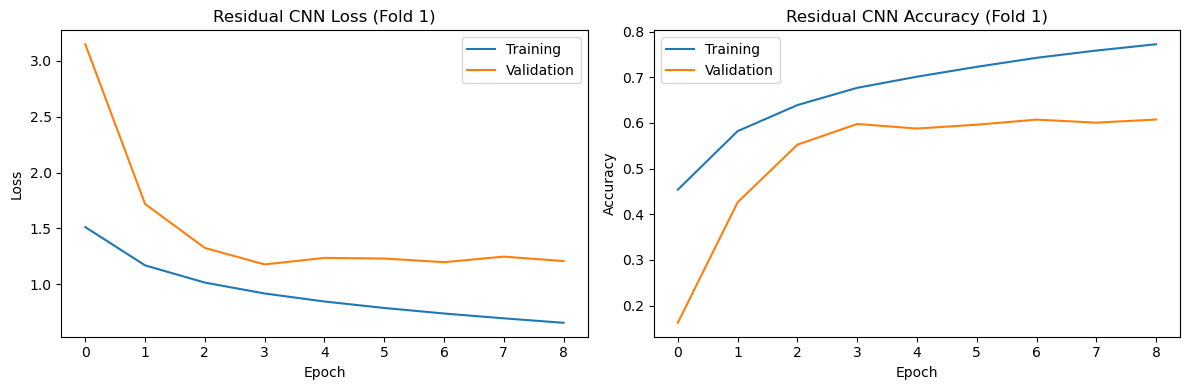

In [49]:
# CNN training history (Fold 1)
history = cifar_cnn_histories[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(
        history[metric],
        label='Training'
    )
    ax.plot(
        history[f'val_{metric}'],
        label='Validation'
    )

    ax.set_title(f'Residual CNN {metric.title()} (Fold 1)')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.title())
    ax.legend()

plt.tight_layout()
plt.show()

#### 2.6.4. CNN Cross-Validation Results Interpretation

Stratified 10-Fold 교차검증 결과 Residual CNN의 평균 정확도는 62.06%, 평균 손실은 1.0957로 나타났다. 정확도 표준편차는 0.0373으로 Fold에 따라 분류 성능에 차이가 있었다.

첫 번째 Fold의 학습 곡선에서는 훈련 정확도가 약 77%까지 상승한 반면 검증 정확도는 약 61%에서 정체되었다. 또한 훈련 손실이 지속적으로 감소하는 동안 검증 손실은 일정 수준 이후 개선되지 않아 과적합이 관찰되었다.

이에 따라 기존 CNN을 Baseline으로 유지하고 과적합 완화를 위한 제한적인 추가 실험을 수행한다.

#### 2.6.5. Data Augmentation Experiment

In [50]:
# CIFAR-10 CNN: Data Augmentation Trial (Fold 1)

train_idx, val_idx = cifar_fold_indices[0]

x_fold_train = cifar_x_train_cnn[train_idx]
y_fold_train = cifar_y_train[train_idx]

x_fit, x_es, y_fit, y_es = train_test_split(
    x_fold_train,
    y_fold_train,
    test_size=0.1,
    stratify=y_fold_train,
    random_state=42
)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(43)

# Data augmentation: training only
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    )
], name="data_augmentation")

# Original CNN architecture
base_cnn = build_cifar_cnn()

inputs = tf.keras.Input(shape=(32, 32, 3))
x = augmentation(inputs)
outputs = base_cnn(x)

cifar_cnn_aug_trial = tf.keras.Model(
    inputs,
    outputs,
    name="CIFAR10_Residual_CNN_Augmented"
)

cifar_cnn_aug_trial.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train one trial model
cifar_cnn_aug_history = cifar_cnn_aug_trial.fit(
    x_fit,
    y_fit,
    validation_data=(x_es, y_es),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

# Results at the epoch with the lowest validation loss
aug_history = cifar_cnn_aug_history.history
aug_best_idx = np.argmin(aug_history["val_loss"])

print("\n=== Augmented CNN Trial ===")
print(f"Best Epoch: {aug_best_idx + 1}")
print(f"Validation Accuracy: {aug_history['val_accuracy'][aug_best_idx]:.4f}")
print(f"Validation Loss: {aug_history['val_loss'][aug_best_idx]:.4f}")

Epoch 1/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 97s 287ms/step - accuracy: 0.4419 - loss: 1.5440 - val_accuracy: 0.2322 - val_loss: 2.4816
Epoch 2/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 87s 274ms/step - accuracy: 0.5604 - loss: 1.2227 - val_accuracy: 0.4536 - val_loss: 1.5853
Epoch 3/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 92s 289ms/step - accuracy: 0.6122 - loss: 1.0892 - val_accuracy: 0.4758 - val_loss: 1.5634
Epoch 4/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 89s 279ms/step - accuracy: 0.6443 - loss: 1.0063 - val_accuracy: 0.5489 - val_loss: 1.3096
Epoch 5/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 104s 328ms/step - accuracy: 0.6587 - loss: 0.9536 - val_accuracy: 0.5656 - val_loss: 1.2447
Epoch 6/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 94s 297ms/step - accuracy: 0.6812 - loss: 0.9018 - val_accuracy: 0.6487 - val_loss: 0.9933
Epoch 7/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 105s 331ms/step - accuracy: 0.6941 - loss: 0.8643 - val_accuracy: 0.6111 - val_loss: 1.1967
Epoch 8/30
317/317 ━━━━━━━━━━━━━━━━━━━━ 98s 308ms/step - accuracy: 0.7051 - loss:

In [51]:
# Compare internal validation performance (Fold 1)

baseline_history = cifar_cnn_histories[0]

baseline_best_idx = np.argmin(
    baseline_history["val_loss"]
)

aug_best_idx = np.argmin(
    cifar_cnn_aug_history.history["val_loss"]
)

trial_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Augmented CNN"
    ],
    "Best Epoch": [
        baseline_best_idx + 1,
        aug_best_idx + 1
    ],
    "Validation Accuracy": [
        baseline_history["val_accuracy"][baseline_best_idx],
        cifar_cnn_aug_history.history["val_accuracy"][aug_best_idx]
    ],
    "Validation Loss": [
        baseline_history["val_loss"][baseline_best_idx],
        cifar_cnn_aug_history.history["val_loss"][aug_best_idx]
    ]
})

print(
    trial_comparison.round(4).to_string(index=False)
)

        Model  Best Epoch  Validation Accuracy  Validation Loss
 Baseline CNN           4               0.5976           1.1773
Augmented CNN          22               0.7669           0.6854


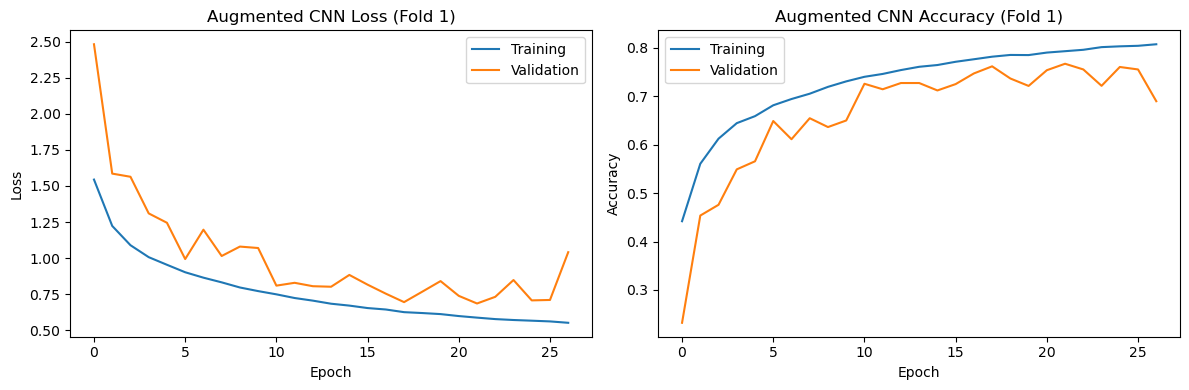

In [52]:
# Augmented CNN training history
history = cifar_cnn_aug_history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        history[metric],
        label="Training"
    )
    ax.plot(
        history[f"val_{metric}"],
        label="Validation"
    )

    ax.set_title(f"Augmented CNN {metric.title()} (Fold 1)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric.title())
    ax.legend()

plt.tight_layout()
plt.show()

#### 2.6.6. Augmented CNN Evaluation

데이터 증강을 적용한 CNN의 성능을 확인하기 위해 첫 번째 Fold의 교차검증용 검증 데이터에서 모델을 평가한다.

기존 CNN과 동일한 검증 데이터를 사용하여 정확도와 손실을 비교한다. 해당 결과는 단일 Fold의 탐색적 평가이므로 전체 10-Fold 교차검증 결과를 대체하지 않는다.

In [53]:
# Fold 1 cross-validation holdout set
_, val_idx = cifar_fold_indices[0]

x_fold_val = cifar_x_train_cnn[val_idx]
y_fold_val = cifar_y_train[val_idx]

# Evaluate the trained augmented CNN
aug_val_loss, aug_val_accuracy = cifar_cnn_aug_trial.evaluate(
    x_fold_val,
    y_fold_val,
    verbose=0
)

# Baseline CNN: Fold 1 result from 10-Fold CV
baseline_fold1 = cifar_cnn_cv_df.loc[
    cifar_cnn_cv_df['Fold'] == 1
].iloc[0]

# Compare on the same held-out fold
cifar_cnn_fold1_comparison = pd.DataFrame({
    'Model': ['Baseline CNN', 'Augmented CNN'],
    'Accuracy': [
        baseline_fold1['Accuracy'],
        aug_val_accuracy
    ],
    'Loss': [
        baseline_fold1['Loss'],
        aug_val_loss
    ]
})

print("=== CIFAR-10 CNN: Fold 1 Comparison ===")
print(
    cifar_cnn_fold1_comparison.round(4).to_string(index=False)
)

print(
    f"\nAccuracy Difference: "
    f"{(aug_val_accuracy - baseline_fold1['Accuracy']) * 100:+.2f}%p"
)

print(
    f"Loss Difference: "
    f"{aug_val_loss - baseline_fold1['Loss']:+.4f}"
)

=== CIFAR-10 CNN: Fold 1 Comparison ===
        Model  Accuracy   Loss
 Baseline CNN    0.5940 1.1756
Augmented CNN    0.7662 0.6888

Accuracy Difference: +17.22%p
Loss Difference: -0.4868


### 2.7. Final Model Training

#### 2.7.1. Final Training Strategy

CIFAR-10의 교차검증 및 추가 실험 결과를 바탕으로 Residual DNN과 데이터 증강을 적용한 Residual CNN을 최종 평가 대상으로 선정하였다.

DNN은 훈련 데이터 내부에서 Early Stopping을 이용해 최적 Epoch를 결정한 뒤 전체 훈련 데이터로 재학습한다. CNN은 데이터 증강 실험에서 검증 손실이 가장 낮았던 22 Epoch를 적용하여 전체 훈련 데이터로 학습한다.

공식 테스트 데이터 10,000개는 최종 모델의 일반화 성능을 평가하는 단계에서만 사용한다.

In [54]:
# Final DNN: epoch selection using internal validation
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

x_fit, x_es, y_fit, y_es = train_test_split(
    cifar_x_train_dnn,
    cifar_y_train,
    test_size=0.1,
    stratify=cifar_y_train,
    random_state=42
)

cifar_dnn_epoch_model = build_cifar_dnn()

dnn_epoch_history = cifar_dnn_epoch_model.fit(
    x_fit,
    y_fit,
    validation_data=(x_es, y_es),
    epochs=30,
    batch_size=128,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

cifar_dnn_best_epoch = int(
    np.argmin(dnn_epoch_history.history['val_loss']) + 1
)

print("\n=== Final DNN Epoch Selection ===")
print(f"Best Epoch: {cifar_dnn_best_epoch}")
print(
    f"Best Validation Loss: "
    f"{min(dnn_epoch_history.history['val_loss']):.4f}"
)

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.3662 - loss: 1.8645 - val_accuracy: 0.3566 - val_loss: 1.8895
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.4647 - loss: 1.5037 - val_accuracy: 0.3824 - val_loss: 1.7478
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.5200 - loss: 1.3567 - val_accuracy: 0.4086 - val_loss: 1.6881
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.5586 - loss: 1.2454 - val_accuracy: 0.4070 - val_loss: 1.7084
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.5910 - loss: 1.1509 - val_accuracy: 0.3966 - val_loss: 1.7181
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6258 - loss: 1.0594 - val_accuracy: 0.4074 - val_loss: 1.8468
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6554 - loss: 0.9727 - val_accuracy: 0.4124 - val_loss: 1.8988
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.6838 - loss: 0.8866 - val_

In [55]:
# Final DNN training on all 50,000 training images
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

cifar_dnn_final = build_cifar_dnn()

cifar_dnn_final_history = cifar_dnn_final.fit(
    cifar_x_train_dnn,
    cifar_y_train,
    epochs=cifar_dnn_best_epoch,
    batch_size=128,
    verbose=1
)

# Save final model
cifar_dnn_final.save('cifar_dnn_final.keras')

print("\nFinal DNN training completed.")
print(f"Training Epochs: {cifar_dnn_best_epoch}")
print("Saved: cifar_dnn_final.keras")

Epoch 1/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.3683 - loss: 1.8527
Epoch 2/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.4694 - loss: 1.4957
Epoch 3/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.5180 - loss: 1.3483

Final DNN training completed.
Training Epochs: 3
Saved: cifar_dnn_final.keras


#### 2.7.2. Final DNN and CNN Training

최종 DNN은 내부 검증에서 선택한 Epoch만큼 전체 훈련 데이터로 학습한다.

최종 CNN은 기존 Residual CNN 구조를 유지하면서 무작위 좌우 반전과 이미지 이동을 적용한다. 데이터 증강은 학습 과정에서만 활성화되며, 최종 평가에서는 원본 이미지를 사용한다.

학습이 완료된 모델은 파일로 저장하여 불필요한 재학습을 방지한다.

In [56]:
# Final augmented CNN
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(43)

# Data augmentation
final_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    )
], name="data_augmentation")

# Original ResNet-based CNN
base_cnn = build_cifar_cnn()

inputs = tf.keras.Input(shape=(32, 32, 3))
x = final_augmentation(inputs)
outputs = base_cnn(x)

cifar_cnn_final = tf.keras.Model(
    inputs,
    outputs,
    name="CIFAR10_Final_Augmented_CNN"
)

cifar_cnn_final.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Final training
CIFAR_CNN_FINAL_EPOCHS = 22

cifar_cnn_final_history = cifar_cnn_final.fit(
    cifar_x_train_cnn,
    cifar_y_train,
    epochs=CIFAR_CNN_FINAL_EPOCHS,
    batch_size=128,
    verbose=1
)

# Save final model
cifar_cnn_final.save("cifar_cnn_final.keras")

print("\nFinal CNN training completed.")
print(f"Training Epochs: {CIFAR_CNN_FINAL_EPOCHS}")
print("Saved: cifar_cnn_final.keras")

Epoch 1/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 128s 307ms/step - accuracy: 0.4556 - loss: 1.5150
Epoch 2/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 119s 304ms/step - accuracy: 0.5800 - loss: 1.1797
Epoch 3/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 122s 311ms/step - accuracy: 0.6268 - loss: 1.0461
Epoch 4/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 196s 501ms/step - accuracy: 0.6583 - loss: 0.9650
Epoch 5/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 158s 404ms/step - accuracy: 0.6805 - loss: 0.9070
Epoch 6/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 119s 303ms/step - accuracy: 0.6966 - loss: 0.8639
Epoch 7/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 127s 324ms/step - accuracy: 0.7087 - loss: 0.8334
Epoch 8/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 121s 308ms/step - accuracy: 0.7204 - loss: 0.7946
Epoch 9/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 153s 335ms/step - accuracy: 0.7296 - loss: 0.7689
Epoch 10/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 130s 332ms/step - accuracy: 0.7400 - loss: 0.7394
Epoch 11/22
391/391 ━━━━━━━━━━━━━━━━━━━━ 122s 313ms/step - accuracy: 0.7492 - loss: 0.7176
Epoch 12

In [57]:
# Save final training histories and settings
with open("cifar_final_training_results.pkl", "wb") as f:
    pickle.dump({
        "DNN_History": cifar_dnn_final_history.history,
        "CNN_History": cifar_cnn_final_history.history,
        "DNN_Epochs": cifar_dnn_best_epoch,
        "CNN_Epochs": CIFAR_CNN_FINAL_EPOCHS
    }, f)

# Verify saved files
for filename in [
    "cifar_dnn_final.keras",
    "cifar_cnn_final.keras",
    "cifar_final_training_results.pkl"
]:
    print(
        f"{filename}: "
        f"{'Saved' if os.path.exists(filename) else 'Not Found'}"
    )

cifar_dnn_final.keras: Saved
cifar_cnn_final.keras: Saved
cifar_final_training_results.pkl: Saved


### 2.8. Final Test Evaluation

#### 2.8.1. Test Performance

최종 학습이 완료된 Residual DNN과 데이터 증강 Residual CNN을 CIFAR-10의 공식 테스트 데이터 10,000개에서 평가한다.

Accuracy, Cross-Entropy Loss, Macro F1-score를 산출하여 두 모델의 분류 성능을 비교한다.

In [58]:
# Evaluate on the official CIFAR-10 test set
dnn_test_loss, dnn_test_acc = cifar_dnn_final.evaluate(
    cifar_x_test_dnn,
    cifar_y_test,
    verbose=0
)

cnn_test_loss, cnn_test_acc = cifar_cnn_final.evaluate(
    cifar_x_test_cnn,
    cifar_y_test,
    verbose=0
)

# Predict test labels
cifar_dnn_pred = np.argmax(
    cifar_dnn_final.predict(cifar_x_test_dnn, verbose=0),
    axis=1
)

cifar_cnn_pred = np.argmax(
    cifar_cnn_final.predict(cifar_x_test_cnn, verbose=0),
    axis=1
)

# Calculate Macro F1-score
dnn_macro_f1 = f1_score(
    cifar_y_test, cifar_dnn_pred, average="macro"
)

cnn_macro_f1 = f1_score(
    cifar_y_test, cifar_cnn_pred, average="macro"
)

# Test performance table
cifar_test_results = pd.DataFrame({
    "Model": ["Residual DNN", "Augmented Residual CNN"],
    "Accuracy": [dnn_test_acc, cnn_test_acc],
    "Loss": [dnn_test_loss, cnn_test_loss],
    "Macro F1": [dnn_macro_f1, cnn_macro_f1]
})

print("=== CIFAR-10 Final Test Results ===")
print(cifar_test_results.round(4).to_string(index=False))

=== CIFAR-10 Final Test Results ===
                 Model  Accuracy   Loss  Macro F1
          Residual DNN    0.3446 2.0360    0.3180
Augmented Residual CNN    0.7220 0.8374    0.7084


#### 2.8.2. Confusion Matrix and Classification Report

두 모델의 Confusion Matrix와 클래스별 Precision, Recall, F1-score를 확인하여 어떤 이미지 범주에서 분류 오류가 발생하는지 분석한다.

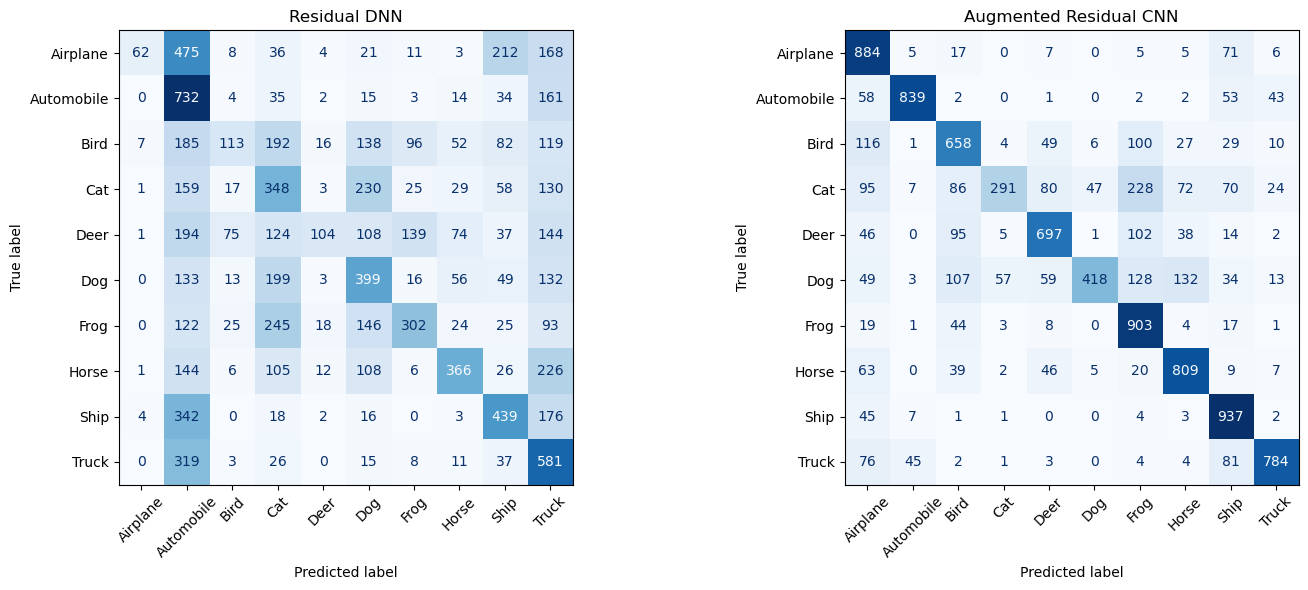

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, y_pred, title in zip(
    axes,
    [cifar_dnn_pred, cifar_cnn_pred],
    ["Residual DNN", "Augmented Residual CNN"]
):
    cm = confusion_matrix(cifar_y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=cifar_class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        xticks_rotation=45
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

In [60]:
print("=== Residual DNN Classification Report ===")
print(
    classification_report(
        cifar_y_test,
        cifar_dnn_pred,
        target_names=cifar_class_names,
        digits=4,
        zero_division=0
    )
)

print("\n=== Augmented Residual CNN Classification Report ===")
print(
    classification_report(
        cifar_y_test,
        cifar_cnn_pred,
        target_names=cifar_class_names,
        digits=4,
        zero_division=0
    )
)

=== Residual DNN Classification Report ===
              precision    recall  f1-score   support

    Airplane     0.8158    0.0620    0.1152      1000
  Automobile     0.2610    0.7320    0.3848      1000
        Bird     0.4280    0.1130    0.1788      1000
         Cat     0.2620    0.3480    0.2990      1000
        Deer     0.6341    0.1040    0.1787      1000
         Dog     0.3336    0.3990    0.3634      1000
        Frog     0.4983    0.3020    0.3761      1000
       Horse     0.5791    0.3660    0.4485      1000
        Ship     0.4394    0.4390    0.4392      1000
       Truck     0.3010    0.5810    0.3966      1000

    accuracy                         0.3446     10000
   macro avg     0.4553    0.3446    0.3180     10000
weighted avg     0.4553    0.3446    0.3180     10000


=== Augmented Residual CNN Classification Report ===
              precision    recall  f1-score   support

    Airplane     0.6092    0.8840    0.7213      1000
  Automobile     0.9240    0.8390  

### 2.9. DNN vs CNN Performance Comparison

최종 테스트 데이터에서 측정한 Residual DNN과 데이터 증강 Residual CNN의 정확도 및 Macro F1-score를 비교한다.

또한 교차검증과 추가 실험 결과를 함께 검토하여 두 모델의 일반화 성능과 이미지 특징 학습 방식의 차이를 분석한다. 단, DNN과 기본 CNN은 10-Fold 교차검증을 수행한 반면 증강 CNN은 단일 Fold에서 추가 검증한 후 최종 모델로 선정했다는 차이가 있다.

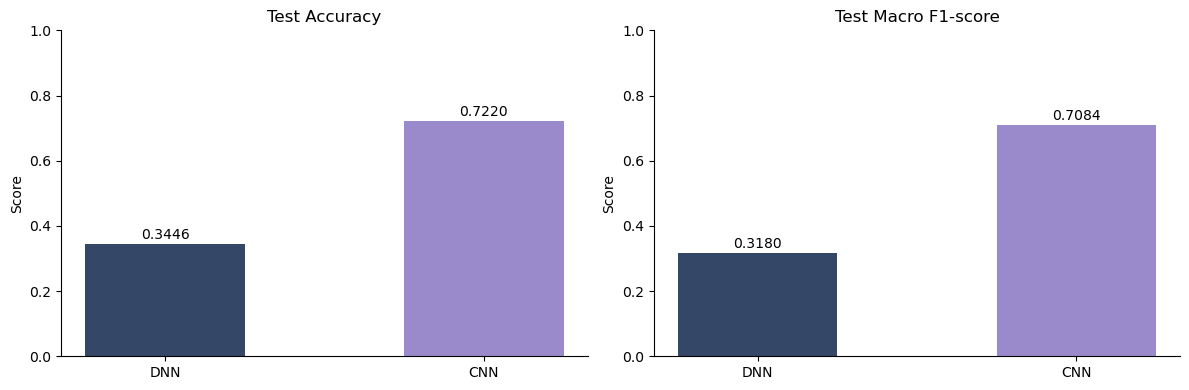

In [61]:
# Final DNN vs CNN comparison
colors = ["#344767", "#9B8ACB"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title in zip(
    axes,
    ["Accuracy", "Macro F1"],
    ["Test Accuracy", "Test Macro F1-score"]
):
    values = cifar_test_results[metric].values

    bars = ax.bar(
        ["DNN", "CNN"],
        values,
        color=colors,
        width=0.5
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.015,
            f"{value:.4f}",
            ha="center"
        )

    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### 2.9.1. Performance Comparison and Interpretation

CIFAR-10 테스트 데이터에서 Residual DNN의 정확도는 34.46%, Macro F1-score는 0.3180으로 나타났다. 반면 데이터 증강을 적용한 Residual CNN은 정확도 72.20%, Macro F1-score 0.7084를 기록하였다. CNN의 정확도는 DNN보다 37.74%p 높았으며, 손실도 2.0360에서 0.8374로 감소하였다.

Confusion Matrix를 분석한 결과 DNN은 특정 클래스에 예측이 집중되는 경향을 보였다. 특히 Airplane, Bird, Deer 클래스의 Recall은 각각 6.2%, 11.3%, 10.4%로 낮았다.

CNN은 10개 클래스 중 9개에서 DNN보다 높은 Recall을 기록하였다. Ship(93.7%), Frog(90.3%), Airplane(88.4%)에서 높은 분류 성능을 보였지만 Cat의 Recall은 29.1%로 상대적으로 낮았으며 Dog와의 혼동이 두드러졌다.

이러한 결과는 이미지의 공간적 특징을 학습하는 CNN의 구조적 장점과 일치한다. 다만 두 모델은 네트워크 구조와 데이터 증강 적용 여부도 다르므로 성능 차이 전체를 합성곱 연산만의 효과로 단정할 수는 없다.

또한 기존 CNN의 10-Fold 평균 정확도 62.06%와 최종 증강 CNN의 테스트 정확도 72.20%는 평가 조건이 다르므로 직접적인 성능 개선 폭으로 해석하지 않는다.

### 2.10. Layer-wise Parameter Analysis

#### 2.10.1. Parameter Calculation

DNN과 CNN의 모델 복잡도를 비교하기 위해 계층별 파라미터 수를 계산한다. 주요 계층의 계산식은 다음과 같다.

- **Dense:** (입력 뉴런 수 × 출력 뉴런 수) + Bias 수
- **Conv2D:** (커널 높이 × 커널 너비 × 입력 채널 수 × 출력 필터 수) + Bias 수
- **Batch Normalization:** 채널당 4개 파라미터(Gamma, Beta, Moving Mean, Moving Variance)
- **Add, Activation, Pooling, Dropout:** 학습 가능한 가중치 파라미터 없음

Batch Normalization의 Gamma와 Beta는 학습 가능한 파라미터이며, Moving Mean과 Moving Variance는 학습 과정에서 갱신되는 비학습 파라미터이다.

최종 CNN은 데이터 증강 계층과 기존 Residual CNN을 결합한 모델이므로, 내부 계층까지 확인하여 파라미터 수를 계산한다.

In [62]:
# Layer-wise parameter analysis
def get_layer_parameters(model):
    rows = []

    def collect_layers(current_model):
        for layer in current_model.layers:
            if isinstance(layer, tf.keras.Model):
                collect_layers(layer)
            else:
                trainable = sum(
                    int(np.prod(w.shape))
                    for w in layer.trainable_weights
                )
                non_trainable = sum(
                    int(np.prod(w.shape))
                    for w in layer.non_trainable_weights
                )

                rows.append({
                    'Layer': layer.name,
                    'Type': layer.__class__.__name__,
                    'Trainable': trainable,
                    'Non-trainable': non_trainable,
                    'Total': trainable + non_trainable
                })

    collect_layers(model)

    return pd.DataFrame(rows)


# DNN parameters
cifar_dnn_param_df = get_layer_parameters(cifar_dnn_final)

# CNN parameters
cifar_cnn_param_df = get_layer_parameters(cifar_cnn_final)

print("=== Residual DNN Layer-wise Parameters ===")
print(cifar_dnn_param_df.to_string(index=False))

print("\n=== Augmented Residual CNN Layer-wise Parameters ===")
print(cifar_cnn_param_df.to_string(index=False))

# Parameter summary
cifar_param_comparison = pd.DataFrame({
    'Model': ['Residual DNN', 'Augmented Residual CNN'],
    'Trainable': [
        cifar_dnn_final.count_params()
        - sum(int(np.prod(w.shape))
              for w in cifar_dnn_final.non_trainable_weights),
        cifar_cnn_final.count_params()
        - sum(int(np.prod(w.shape))
              for w in cifar_cnn_final.non_trainable_weights)
    ],
    'Non-trainable': [
        sum(int(np.prod(w.shape))
            for w in cifar_dnn_final.non_trainable_weights),
        sum(int(np.prod(w.shape))
            for w in cifar_cnn_final.non_trainable_weights)
    ],
    'Total': [
        cifar_dnn_final.count_params(),
        cifar_cnn_final.count_params()
    ]
})

print("\n=== Parameter Comparison ===")
print(cifar_param_comparison.to_string(index=False))

# Verify layer-wise totals
assert cifar_dnn_param_df['Total'].sum() == cifar_dnn_final.count_params()
assert cifar_cnn_param_df['Total'].sum() == cifar_cnn_final.count_params()

print("\nLayer-wise parameter totals verified.")

=== Residual DNN Layer-wise Parameters ===
                Layer               Type  Trainable  Non-trainable  Total
          input_layer         InputLayer          0              0      0
                dense              Dense     786432              0 786432
  batch_normalization BatchNormalization        512            512   1024
           activation         Activation          0              0      0
              dense_1              Dense      65536              0  65536
batch_normalization_1 BatchNormalization        512            512   1024
         activation_1         Activation          0              0      0
              dense_2              Dense      65536              0  65536
batch_normalization_2 BatchNormalization        512            512   1024
                  add                Add          0              0      0
         activation_2         Activation          0              0      0
              dense_3              Dense      65536              0  6

#### 2.10.2. Parameter Comparison

Residual DNN의 전체 파라미터 수는 1,056,266개이며, Augmented Residual CNN은 78,714개이다.

주요 계층의 계산 예시는 다음과 같다.

**1. Residual DNN**

- 최초 Dense 계층: 3,072 × 256 = 786,432개
- 최초 Batch Normalization: 256 × 4 = 1,024개
- Residual Block 내부 Dense(256 → 256): 256 × 256 = 65,536개
- 출력 Dense(256 → 10): (256 × 10) + 10 = 2,570개

**2. Augmented Residual CNN**

- 최초 Conv2D(3×3, 입력 채널 3, 필터 16): 3 × 3 × 3 × 16 = 432개
- 최초 Batch Normalization: 16 × 4 = 64개
- Conv2D(3×3, 입력 채널 16, 필터 32): 3 × 3 × 16 × 32 = 4,608개
- 출력 Dense(64 → 10): (64 × 10) + 10 = 650개

두 모델 모두 Batch Normalization과 Residual Connection을 포함하지만, DNN은 완전연결 계층을 사용하고 CNN은 합성곱 계층의 가중치를 이미지의 여러 위치에서 공유한다.

CNN은 DNN보다 적은 파라미터를 사용하면서도 더 높은 테스트 정확도를 기록하였다. 이는 CNN이 이미지의 공간적 특징을 상대적으로 효율적으로 학습할 수 있음을 보여준다.

각 모델의 전체 파라미터 수는 계층별 가중치, 편향 및 Batch Normalization 관련 파라미터를 합산하여 계산하였다.

$$
P_{\text{total}} = \sum_{l=1}^{L} P_l
$$

Batch Normalization의 전체 파라미터에는 학습 가능한 Gamma와 Beta뿐 아니라 비학습 상태 변수인 Moving Mean과 Moving Variance도 포함된다. 따라서 전체 파라미터 수와 학습 가능한 파라미터 수를 구분하였다.

Residual Connection의 Add 연산과 데이터 증강 계층은 별도의 학습 가능한 파라미터를 추가하지 않는다.

계층별 파라미터 합계는 Keras의 `count_params()` 결과와 비교하여 일치함을 검증하였다.

### 2.11. Conclusion

CIFAR-10 이미지 분류를 위해 Batch Normalization과 Residual Connection을 적용한 Residual DNN과 Residual CNN을 구성하고 성능을 비교하였다.

초기 모델의 Stratified 10-Fold 교차검증에서 DNN은 평균 정확도 38.74%, CNN은 62.06%를 기록하였다. 이후 CNN에 무작위 좌우 반전과 이미지 이동을 적용한 결과, 첫 번째 Fold의 검증 정확도가 개선되었으며 최종 모델에 데이터 증강을 적용하였다.

최종 테스트 데이터에서 DNN의 정확도는 34.46%, Macro F1-score는 0.3180이었고, 증강 CNN은 정확도 72.20%, Macro F1-score 0.7084를 기록하였다.

CNN은 DNN보다 적은 파라미터로 높은 분류 성능을 보였으며, 이미지의 공간적 특징을 활용하는 구조가 CIFAR-10 분류에 유리함을 확인하였다. 다만 Cat과 Dog의 혼동처럼 일부 클래스에서 분류 오류가 남아 있었다.

또한 최종 CNN에만 데이터 증강을 적용했으므로 성능 차이를 네트워크 구조만의 효과로 해석하는 데에는 한계가 있다.

종합적으로 본 실험에서는 CNN이 DNN보다 우수한 분류 성능을 보였으며, 데이터 증강을 통한 일반화 성능 개선 가능성도 확인하였다.

## 3. Bikeshare

### 3.1. Data Loading

In [63]:
# Load Bikeshare dataset
bike_df = pd.read_csv('bike.csv')

# Dataset overview
print("Dataset Shape:", bike_df.shape)

print("\n=== First 5 Rows ===")
display(bike_df.head())

print("\n=== Data Information ===")
bike_df.info()

Dataset Shape: (8645, 16)

=== First 5 Rows ===


,Unnamed: 0,season,mnth,day,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,bikers
0,1,1,Jan,1,0,0,6,0,clear,0.24,0.2879,0.81,0.0,3,13,16
1,2,1,Jan,1,1,0,6,0,clear,0.22,0.2727,0.80,0.0,8,32,40
2,3,1,Jan,1,2,0,6,0,clear,0.22,0.2727,0.80,0.0,5,27,32
3,4,1,Jan,1,3,0,6,0,clear,0.24,0.2879,0.75,0.0,3,10,13
4,5,1,Jan,1,4,0,6,0,clear,0.24,0.2879,0.75,0.0,0,1,1



=== Data Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8645 entries, 0 to 8644
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8645 non-null   int64  
 1   season      8645 non-null   int64  
 2   mnth        8645 non-null   object 
 3   day         8645 non-null   int64  
 4   hr          8645 non-null   int64  
 5   holiday     8645 non-null   int64  
 6   weekday     8645 non-null   int64  
 7   workingday  8645 non-null   int64  
 8   weathersit  8645 non-null   object 
 9   temp        8645 non-null   float64
 10  atemp       8645 non-null   float64
 11  hum         8645 non-null   float64
 12  windspeed   8645 non-null   float64
 13  casual      8645 non-null   int64  
 14  registered  8645 non-null   int64  
 15  bikers      8645 non-null   int64  
dtypes: float64(4), int64(10), object(2)
memory usage: 1.1+ MB


### 3.2. Exploratory Data Analysis (EDA)

In [64]:
# Missing values
print("=== Missing Values ===")
print(bike_df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", bike_df.duplicated().sum())

# Descriptive statistics
print("\n=== Descriptive Statistics ===")
display(bike_df.describe(include='all').T)

# Target consistency
print(
    "\nTarget consistency:",
    (bike_df['bikers'] == (
        bike_df['casual'] + bike_df['registered']
    )).all()
)

=== Missing Values ===
Unnamed: 0    0
season        0
mnth          0
day           0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
bikers        0
dtype: int64

Duplicate Rows: 0

=== Descriptive Statistics ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,8645.0,NaN,NaN,NaN,4323.0,2495.740872,1.0,2162.0,4323.0,6484.0,8645.0
season,8645.0,NaN,NaN,NaN,2.513592,1.105477,1.0,2.0,3.0,3.0,4.0
mnth,8645,12,May,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,8645.0,NaN,NaN,NaN,184.39572,104.82334,1.0,94.0,185.0,275.0,365.0
hr,8645.0,NaN,NaN,NaN,11.573626,6.907822,0.0,6.0,12.0,18.0,23.0
holiday,8645.0,NaN,NaN,NaN,0.027646,0.163966,0.0,0.0,0.0,0.0,1.0
weekday,8645.0,NaN,NaN,NaN,3.012724,2.00637,0.0,1.0,3.0,5.0,6.0
workingday,8645.0,NaN,NaN,NaN,0.683748,0.46504,0.0,0.0,1.0,1.0,1.0
weathersit,8645,4,clear,5645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,8645.0,NaN,NaN,NaN,0.489069,0.197943,0.02,0.32,0.5,0.66,0.96



Target consistency: True


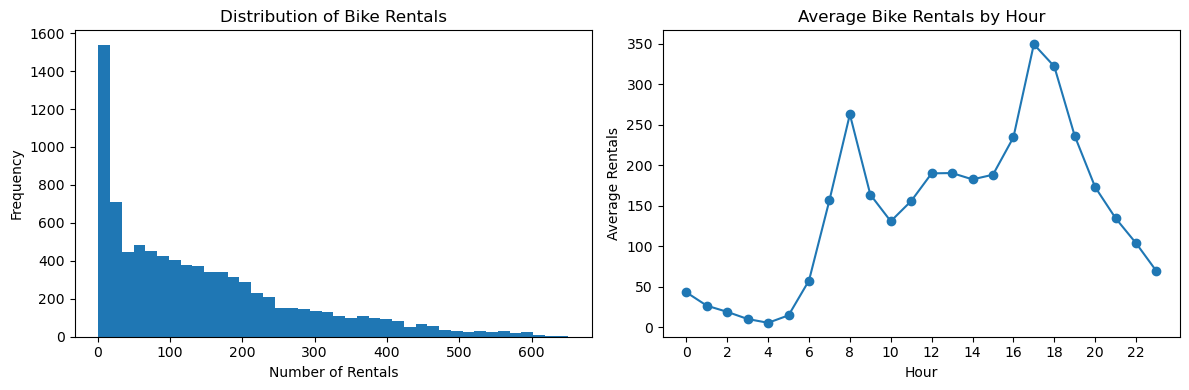

In [65]:
# Distribution of bike rentals
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(bike_df['bikers'], bins=40)
axes[0].set_title('Distribution of Bike Rentals')
axes[0].set_xlabel('Number of Rentals')
axes[0].set_ylabel('Frequency')

# Average rentals by hour
hourly_mean = bike_df.groupby('hr')['bikers'].mean()

axes[1].plot(
    hourly_mean.index,
    hourly_mean.values,
    marker='o'
)
axes[1].set_title('Average Bike Rentals by Hour')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Average Rentals')
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

#### 3.2.1. EDA Results

Bikeshare 데이터는 8,645개의 관측치와 16개의 변수로 구성되어 있으며, 결측치와 중복 행은 발견되지 않았다.

예측 대상인 `bikers`는 평균 143.79건, 최댓값 651건으로 나타났으며, 대여량 분포는 오른쪽으로 긴 꼬리를 가지는 우측 편향 형태를 보였다.

시간대별 평균 대여량은 오전 8시와 오후 17~18시에 높게 나타나 출퇴근 시간대와 자전거 이용량 사이에 관련성이 있을 가능성을 확인하였다.

또한 `bikers`가 `casual`과 `registered`의 합과 일치하므로 두 변수는 데이터 누수 방지를 위해 입력 변수에서 제외한다. 문자형 변수인 `mnth`와 `weathersit`은 모델 학습 전에 인코딩이 필요하다.

### 3.3. Data Preprocessing

Bikeshare 데이터의 자전거 대여량(`bikers`)을 예측하기 위해 입력 변수와 타깃 변수를 분리한다.

`Unnamed: 0`은 행 식별용 변수이며, `casual`과 `registered`는 총 대여량을 직접 구성하는 변수이므로 데이터 누수를 방지하기 위해 제외한다.

시간에 따른 예측 성능을 평가하기 위해 날짜 순서에 따라 전체 데이터의 앞 80%를 훈련 데이터, 뒤 20%를 테스트 데이터로 분할한다. 동일 날짜의 관측치가 두 집합에 나뉘지 않도록 날짜를 기준으로 분할한다.

문자형 범주 변수에는 One-Hot Encoding을 적용하고 테스트 데이터의 인코딩 열을 훈련 데이터의 열 구조에 맞춰 정렬한다.

신경망 모델에는 StandardScaler를 적용하며, 평균과 표준편차는 훈련 데이터에서만 계산한다. Random Forest에는 스케일링하지 않은 인코딩 데이터를 사용한다.

내부 검증 과정에서는 별도의 StandardScaler를 내부 훈련 데이터에만 적합하여 검증 데이터의 정보가 스케일링에 반영되지 않도록 한다.

In [66]:
# Remove identifier and target-derived variables
bike_model_df = bike_df.drop(
    columns=['Unnamed: 0', 'casual', 'registered']
).copy()

# Ensure chronological order
bike_model_df = bike_model_df.sort_values(
    ['day', 'hr']
).reset_index(drop=True)

# Split by date to avoid overlap between train and test
unique_days = bike_model_df['day'].unique()
split_idx = int(len(unique_days) * 0.8)
split_day = unique_days[split_idx]

bike_train_df = bike_model_df[
    bike_model_df['day'] < split_day
].copy()

bike_test_df = bike_model_df[
    bike_model_df['day'] >= split_day
].copy()

# Separate features and target
X_train_raw = bike_train_df.drop(columns='bikers')
X_test_raw = bike_test_df.drop(columns='bikers')

y_train = bike_train_df['bikers'].to_numpy()
y_test = bike_test_df['bikers'].to_numpy()

print("=== Train/Test Split ===")
print("Training:", X_train_raw.shape)
print("Test:", X_test_raw.shape)
print("Training days:", bike_train_df['day'].min(),
      "-", bike_train_df['day'].max())
print("Test days:", bike_test_df['day'].min(),
      "-", bike_test_df['day'].max())
print("Target:", 'bikers')

=== Train/Test Split ===
Training: (6897, 12)
Test: (1748, 12)
Training days: 1 - 292
Test days: 293 - 365
Target: bikers


In [67]:
from sklearn.preprocessing import StandardScaler

# Categorical variables
bike_categorical_cols = [
    'season', 'mnth', 'hr', 'weekday', 'weathersit'
]

# One-Hot Encoding
X_train_encoded = pd.get_dummies(
    X_train_raw,
    columns=bike_categorical_cols,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_raw,
    columns=bike_categorical_cols,
    dtype=int
)

# Match test features to training features
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

bike_feature_names = X_train_encoded.columns.tolist()

# Random Forest: unscaled features
X_train_rf = X_train_encoded.to_numpy(dtype='float32')
X_test_rf = X_test_encoded.to_numpy(dtype='float32')

# Neural networks: standardized features
bike_scaler = StandardScaler()

X_train_nn = bike_scaler.fit_transform(
    X_train_encoded
).astype('float32')

X_test_nn = bike_scaler.transform(
    X_test_encoded
).astype('float32')

print("=== Preprocessed Data Shapes ===")
print("DNN Training:", X_train_nn.shape)
print("DNN Test:", X_test_nn.shape)
print("RF Training:", X_train_rf.shape)
print("RF Test:", X_test_rf.shape)
print("Number of Features:", len(bike_feature_names))

print("\nMissing values after preprocessing:")
print("Train:", np.isnan(X_train_nn).sum())
print("Test:", np.isnan(X_test_nn).sum())

=== Preprocessed Data Shapes ===
DNN Training: (6897, 56)
DNN Test: (1748, 56)
RF Training: (6897, 56)
RF Test: (1748, 56)
Number of Features: 56

Missing values after preprocessing:
Train: 0
Test: 0


In [68]:
# Reshape for 1D-CNN
X_train_cnn1d = X_train_nn.reshape(
    X_train_nn.shape[0],
    X_train_nn.shape[1],
    1
)

X_test_cnn1d = X_test_nn.reshape(
    X_test_nn.shape[0],
    X_test_nn.shape[1],
    1
)

print("=== Model Input Shapes ===")
print("DNN:", X_train_nn.shape)
print("1D-CNN:", X_train_cnn1d.shape)
print("Random Forest:", X_train_rf.shape)

=== Model Input Shapes ===
DNN: (6897, 56)
1D-CNN: (6897, 56, 1)
Random Forest: (6897, 56)


### 3.4. Model Training and Evaluation

#### 3.4.1. DNN Model

Bikeshare 대여량 예측을 위해 완전연결 신경망(DNN)을 구성한다. 은닉층에는 ReLU 활성화 함수를 적용하고, 출력층에는 회귀 문제에 적합한 선형 활성화 함수를 사용한다.

모델 비교를 위해 훈련 기간의 마지막 20%를 내부 검증 데이터로 분리한다. 검증 기간 이후의 정보를 학습에 사용하지 않으며, RMSE, MAE, R²를 통해 예측 성능을 평가한다.

In [69]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Chronological train/validation split
bike_train_days = bike_train_df['day'].unique()
val_start_day = bike_train_days[int(len(bike_train_days) * 0.8)]

fit_mask = (bike_train_df['day'] < val_start_day).to_numpy()
val_mask = ~fit_mask

# Fit scaler using internal training data only
bike_internal_scaler = StandardScaler()

X_fit_nn = bike_internal_scaler.fit_transform(
    X_train_encoded.iloc[fit_mask]
).astype('float32')

X_val_nn = bike_internal_scaler.transform(
    X_train_encoded.iloc[val_mask]
).astype('float32')

y_fit = y_train[fit_mask].astype('float32')
y_val = y_train[val_mask].astype('float32')

print("Internal Training:", X_fit_nn.shape)
print("Internal Validation:", X_val_nn.shape)
print("Training Period:", bike_train_df.loc[fit_mask, 'day'].min(),
      "-", bike_train_df.loc[fit_mask, 'day'].max())
print("Validation Period:", bike_train_df.loc[val_mask, 'day'].min(),
      "-", bike_train_df.loc[val_mask, 'day'].max())

Internal Training: (5498, 56)
Internal Validation: (1399, 56)
Training Period: 1 - 233
Validation Period: 234 - 292


In [70]:
def build_bike_dnn(n_features):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1)
    ], name='Bikeshare_DNN')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )
    return model


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

bike_dnn = build_bike_dnn(X_fit_nn.shape[1])

bike_dnn_history = bike_dnn.fit(
    X_fit_nn,
    y_fit,
    validation_data=(X_val_nn, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=0
)

bike_dnn_pred_val = bike_dnn.predict(
    X_val_nn, verbose=0
).ravel()

bike_dnn_rmse = np.sqrt(
    mean_squared_error(y_val, bike_dnn_pred_val)
)
bike_dnn_mae = mean_absolute_error(y_val, bike_dnn_pred_val)
bike_dnn_r2 = r2_score(y_val, bike_dnn_pred_val)

print("=== Bikeshare DNN Validation Results ===")
print(f"RMSE: {bike_dnn_rmse:.4f}")
print(f"MAE : {bike_dnn_mae:.4f}")
print(f"R²  : {bike_dnn_r2:.4f}")
print(f"Epochs Trained: {len(bike_dnn_history.history['loss'])}")

=== Bikeshare DNN Validation Results ===
RMSE: 52.8367
MAE : 34.1407
R²  : 0.8780
Epochs Trained: 58


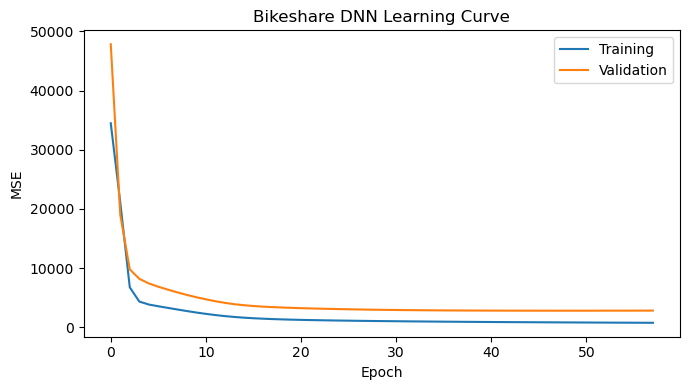

In [71]:
plt.figure(figsize=(7, 4))

plt.plot(
    bike_dnn_history.history['loss'],
    label='Training'
)
plt.plot(
    bike_dnn_history.history['val_loss'],
    label='Validation'
)

plt.title('Bikeshare DNN Learning Curve')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()

#### 3.4.2. 1D-CNN Model

Bikeshare 대여량 예측을 위해 1D-CNN을 구성한다. 전처리된 입력 변수에 채널 차원을 추가한 뒤 Conv1D 계층으로 특징을 추출하고 Dense 출력층에서 대여량을 예측한다. 합성곱 계층에서 추출한 위치별 특징 정보를 유지하기 위해 Flatten 계층을 사용하고 완전연결 계층을 통해 최종 대여량을 예측한다.


DNN과 동일한 내부 훈련·검증 데이터를 사용하며, Early Stopping을 적용한다. 다만 입력 데이터는 시간 순서로 구성된 시계열 윈도우가 아닌 표 형식의 변수들이므로 인접 변수에 대한 합성곱 적용에는 구조적 한계가 있다.

In [72]:
# Reshape internal training and validation data
X_fit_cnn1d = X_fit_nn.reshape(-1, X_fit_nn.shape[1], 1)
X_val_cnn1d = X_val_nn.reshape(-1, X_val_nn.shape[1], 1)


def build_bike_cnn1d(n_features):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features, 1)),

        tf.keras.layers.Conv1D(
            32, kernel_size=3, padding='same',
            activation='relu'
        ),
        tf.keras.layers.MaxPooling1D(pool_size=2),

        tf.keras.layers.Conv1D(
            64, kernel_size=3, padding='same',
            activation='relu'
        ),
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(1)
    ], name='Bikeshare_1D_CNN')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )

    return model


# Train 1D-CNN
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

bike_cnn1d = build_bike_cnn1d(X_fit_nn.shape[1])

bike_cnn1d_history = bike_cnn1d.fit(
    X_fit_cnn1d,
    y_fit,
    validation_data=(X_val_cnn1d, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=0
)

# Validation predictions
bike_cnn1d_pred_val = bike_cnn1d.predict(
    X_val_cnn1d, verbose=0
).ravel()

bike_cnn1d_rmse = np.sqrt(
    mean_squared_error(y_val, bike_cnn1d_pred_val)
)
bike_cnn1d_mae = mean_absolute_error(
    y_val, bike_cnn1d_pred_val
)
bike_cnn1d_r2 = r2_score(
    y_val, bike_cnn1d_pred_val
)

print("=== Bikeshare 1D-CNN Validation Results ===")
print(f"RMSE: {bike_cnn1d_rmse:.4f}")
print(f"MAE : {bike_cnn1d_mae:.4f}")
print(f"R²  : {bike_cnn1d_r2:.4f}")
print(f"Epochs Trained: {len(bike_cnn1d_history.history['loss'])}")

=== Bikeshare 1D-CNN Validation Results ===
RMSE: 63.3657
MAE : 42.9667
R²  : 0.8246
Epochs Trained: 40


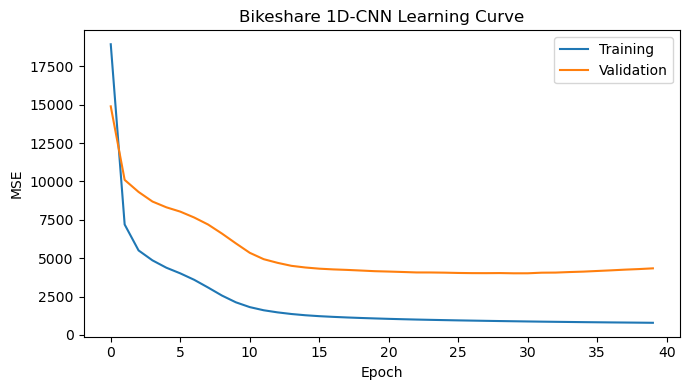

In [73]:
# 1D-CNN learning curve
plt.figure(figsize=(7, 4))

plt.plot(
    bike_cnn1d_history.history['loss'],
    label='Training'
)
plt.plot(
    bike_cnn1d_history.history['val_loss'],
    label='Validation'
)

plt.title('Bikeshare 1D-CNN Learning Curve')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

plt.tight_layout()
plt.show()

#### 3.4.3. Random Forest Model

Bikeshare 대여량 예측을 위해 Random Forest 회귀 모델을 구성한다. Random Forest는 여러 의사결정나무의 예측값을 평균하여 최종 예측값을 산출하는 앙상블 학습 방법이다.

DNN 및 1D-CNN과 동일한 내부 훈련·검증 기간을 사용하여 RMSE, MAE, R²를 비교한다. Random Forest는 변수 스케일링이 필수적이지 않으므로 One-Hot Encoding을 적용한 데이터를 사용한다.

In [74]:
from sklearn.ensemble import RandomForestRegressor

# Internal training and validation data
X_fit_rf = X_train_rf[fit_mask]
X_val_rf = X_train_rf[val_mask]

# Random Forest model
bike_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Model training
bike_rf.fit(X_fit_rf, y_fit)

# Validation predictions
bike_rf_pred_val = bike_rf.predict(X_val_rf)

# Evaluation
bike_rf_rmse = np.sqrt(
    mean_squared_error(y_val, bike_rf_pred_val)
)
bike_rf_mae = mean_absolute_error(
    y_val, bike_rf_pred_val
)
bike_rf_r2 = r2_score(
    y_val, bike_rf_pred_val
)

print("=== Bikeshare Random Forest Validation Results ===")
print(f"RMSE: {bike_rf_rmse:.4f}")
print(f"MAE : {bike_rf_mae:.4f}")
print(f"R²  : {bike_rf_r2:.4f}")

=== Bikeshare Random Forest Validation Results ===
RMSE: 77.3034
MAE : 49.6180
R²  : 0.7389


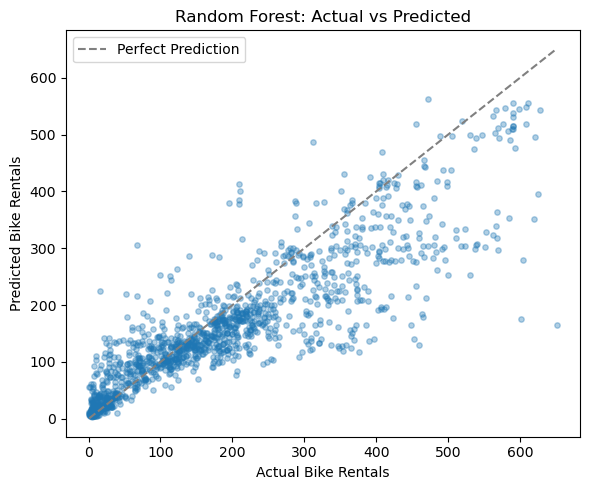

In [75]:
# Random Forest: Actual vs Predicted
plt.figure(figsize=(6, 5))

plt.scatter(
    y_val,
    bike_rf_pred_val,
    alpha=0.35,
    s=15
)

min_val = min(y_val.min(), bike_rf_pred_val.min())
max_val = max(y_val.max(), bike_rf_pred_val.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    color='gray',
    label='Perfect Prediction'
)

plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual Bike Rentals')
plt.ylabel('Predicted Bike Rentals')
plt.legend()
plt.tight_layout()
plt.show()

#### 3.4.4. Validation Performance Comparison

동일한 내부 검증 데이터에서 DNN, 1D-CNN, Random Forest의 예측 성능을 비교한다. RMSE와 MAE는 낮을수록, R²는 높을수록 우수한 성능을 의미한다.

In [76]:
# Validation performance comparison
bike_val_results = pd.DataFrame({
    'Model': ['DNN', '1D-CNN', 'Random Forest'],
    'RMSE': [
        bike_dnn_rmse,
        bike_cnn1d_rmse,
        bike_rf_rmse
    ],
    'MAE': [
        bike_dnn_mae,
        bike_cnn1d_mae,
        bike_rf_mae
    ],
    'R²': [
        bike_dnn_r2,
        bike_cnn1d_r2,
        bike_rf_r2
    ]
})

print("=== Bikeshare Validation Performance ===")
print(bike_val_results.round(4).to_string(index=False))

=== Bikeshare Validation Performance ===
        Model    RMSE     MAE     R²
          DNN 52.8367 34.1407 0.8780
       1D-CNN 63.3657 42.9667 0.8246
Random Forest 77.3034 49.6180 0.7389


### 3.5. Final Model Training

내부 검증 결과를 바탕으로 DNN, 1D-CNN, Random Forest의 최종 모델을 학습한다.

DNN과 1D-CNN은 검증 손실이 가장 낮았던 Epoch를 선택하고 Random Forest는 기존 초모수를 유지한다. 세 모델 모두 전체 훈련 데이터로 재학습하며, 테스트 데이터는 최종 성능 평가에만 사용한다.

In [77]:
import joblib

# Select epochs using minimum validation loss
bike_dnn_best_epoch = (
    np.argmin(bike_dnn_history.history['val_loss']) + 1
)
bike_cnn1d_best_epoch = (
    np.argmin(bike_cnn1d_history.history['val_loss']) + 1
)

print("DNN Best Epoch:", bike_dnn_best_epoch)
print("1D-CNN Best Epoch:", bike_cnn1d_best_epoch)

# Final DNN
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

bike_dnn_final = build_bike_dnn(X_train_nn.shape[1])
bike_dnn_final.fit(
    X_train_nn, y_train,
    epochs=bike_dnn_best_epoch,
    batch_size=64,
    verbose=0
)
bike_dnn_final.save('bike_dnn_final.keras')

# Final 1D-CNN
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

bike_cnn1d_final = build_bike_cnn1d(X_train_nn.shape[1])
bike_cnn1d_final.fit(
    X_train_cnn1d, y_train,
    epochs=bike_cnn1d_best_epoch,
    batch_size=64,
    verbose=0
)
bike_cnn1d_final.save('bike_cnn1d_final.keras')

# Final Random Forest
bike_rf_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
bike_rf_final.fit(X_train_rf, y_train)
joblib.dump(bike_rf_final, 'bike_rf_final.joblib')

# Save preprocessing objects
joblib.dump(bike_scaler, 'bike_scaler.joblib')
joblib.dump(bike_feature_names, 'bike_feature_names.joblib')

print("\nAll final Bikeshare models saved.")

DNN Best Epoch: 48
1D-CNN Best Epoch: 30

All final Bikeshare models saved.


### 3.6. Final Test Evaluation

최종 학습한 DNN, 1D-CNN, Random Forest를 테스트 데이터에 적용하여 예측 성능을 평가한다.

세 모델은 동일한 테스트 기간(293~365일)의 1,748개 관측치를 사용하며, RMSE, MAE, R²를 기준으로 비교한다.

In [78]:
# Load saved models
bike_dnn_final = tf.keras.models.load_model(
    'bike_dnn_final.keras', compile=False
)
bike_cnn1d_final = tf.keras.models.load_model(
    'bike_cnn1d_final.keras', compile=False
)
bike_rf_final = joblib.load('bike_rf_final.joblib')

# Test predictions
bike_dnn_pred_test = bike_dnn_final.predict(
    X_test_nn, verbose=0
).ravel()

bike_cnn1d_pred_test = bike_cnn1d_final.predict(
    X_test_cnn1d, verbose=0
).ravel()

bike_rf_pred_test = bike_rf_final.predict(X_test_rf)

# Evaluation function
def bike_regression_metrics(y_true, y_pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R²': r2_score(y_true, y_pred)
    }

bike_test_results = pd.DataFrame([
    {'Model': 'DNN', **bike_regression_metrics(y_test, bike_dnn_pred_test)},
    {'Model': '1D-CNN', **bike_regression_metrics(y_test, bike_cnn1d_pred_test)},
    {'Model': 'Random Forest', **bike_regression_metrics(y_test, bike_rf_pred_test)}
])

print("=== Bikeshare Final Test Results ===")
print(bike_test_results.round(4).to_string(index=False))

=== Bikeshare Final Test Results ===
        Model    RMSE     MAE     R²
          DNN 59.7700 38.6109 0.7515
       1D-CNN 49.3483 31.5472 0.8306
Random Forest 63.4381 43.5100 0.7200


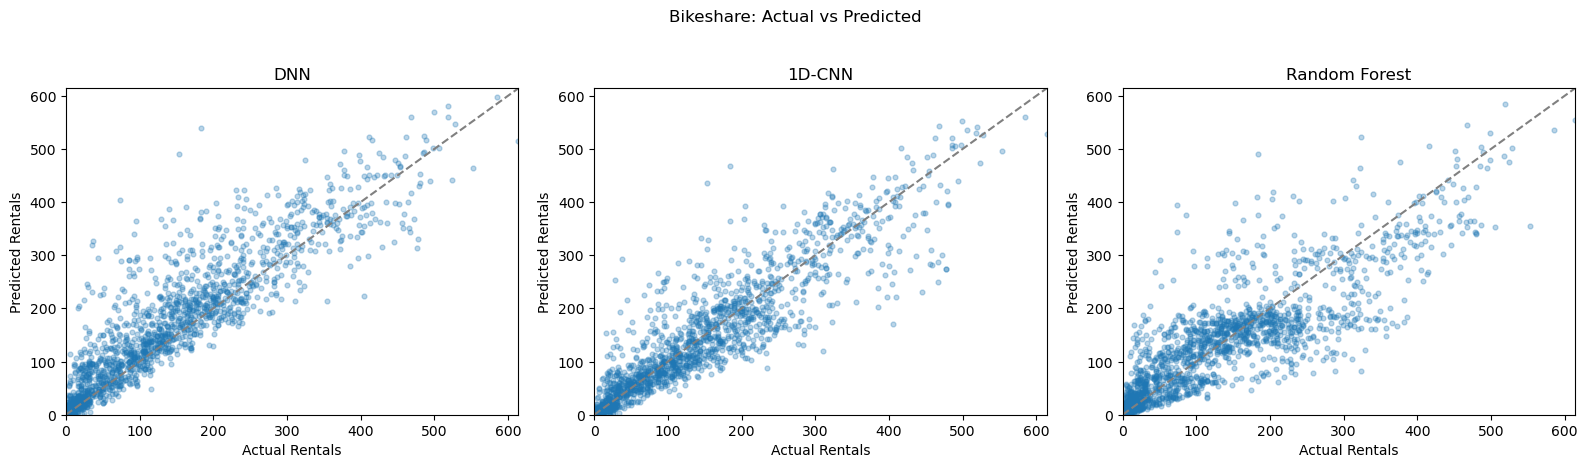

In [79]:
# Actual vs Predicted: Final model comparison
predictions = [
    bike_dnn_pred_test,
    bike_cnn1d_pred_test,
    bike_rf_pred_test
]

models = ['DNN', '1D-CNN', 'Random Forest']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

plot_max = max(
    y_test.max(),
    *(pred.max() for pred in predictions)
)

for ax, model_name, pred in zip(axes, models, predictions):
    ax.scatter(y_test, pred, alpha=0.3, s=12)

    ax.plot(
        [0, plot_max], [0, plot_max],
        linestyle='--',
        color='gray'
    )

    ax.set_title(model_name)
    ax.set_xlabel('Actual Rentals')
    ax.set_ylabel('Predicted Rentals')
    ax.set_xlim(0, plot_max)
    ax.set_ylim(0, plot_max)

plt.suptitle('Bikeshare: Actual vs Predicted', y=1.03)
plt.tight_layout()
plt.show()

#### 3.6.1. Test Performance Interpretation

최종 테스트 데이터에서 1D-CNN은 RMSE 49.3483, MAE 31.5472, R² 0.8306으로 세 모델 중 가장 우수한 예측 성능을 기록하였다.

DNN은 R² 0.7515, Random Forest는 0.7200으로 나타났다. 내부 검증에서는 DNN이 가장 우수했지만 최종 테스트에서는 1D-CNN이 더 높은 성능을 보여 평가 기간에 따라 모델의 상대적 성능이 달라질 수 있음을 확인하였다.

Actual vs Predicted 그래프에서는 세 모델 모두 실제 대여량이 증가할수록 예측값도 증가하는 경향을 보였다. 다만 높은 대여량 구간에서는 예측 오차가 커졌으며, 특히 Random Forest에서 과소예측 경향이 두드러졌다.

본 결과는 테스트 기간의 예측 성능을 나타내며, 모든 기간에서 동일한 모델 순위가 유지된다는 의미는 아니다.

### 3.7. Feature Importance Analysis

In [80]:
# Original feature names
bike_original_features = X_train_raw.columns.tolist()

# Convert string categories into numeric codes for SHAP
bike_category_maps = {}

X_train_explain = X_train_raw.copy()
X_test_explain = X_test_raw.copy()

for col in X_train_raw.select_dtypes(
    include=['object', 'category']
).columns:
    categories = sorted(
    pd.concat([
        X_train_raw[col],
        X_test_raw[col]
    ]).dropna().unique()
)

    forward_map = {
        value: idx for idx, value in enumerate(categories)
    }
    reverse_map = {
        idx: value for idx, value in enumerate(categories)
    }

    bike_category_maps[col] = reverse_map

    X_train_explain[col] = X_train_raw[col].map(forward_map)
    X_test_explain[col] = X_test_raw[col].map(forward_map)

assert not X_train_explain.isna().any().any()
assert not X_test_explain.isna().any().any()

# Corrected preprocessing function for feature importance
def prepare_bike_features(X):
    X = pd.DataFrame(
        np.asarray(X),
        columns=bike_original_features
    ).copy()

    # Restore original categorical labels
    for col, reverse_map in bike_category_maps.items():
        X[col] = X[col].round().astype(int).map(reverse_map)

    # Restore original categorical data types
    for col in bike_categorical_cols:
        X[col] = X[col].astype(X_train_raw[col].dtype)

    # Apply the same One-Hot Encoding as training
    X_encoded = pd.get_dummies(
        X,
        columns=bike_categorical_cols,
        dtype=int
    ).reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    )

    X_nn = bike_scaler.transform(
        X_encoded
    ).astype('float32')

    X_rf = X_encoded.to_numpy(dtype='float32')

    return X_nn, X_rf



# Common prediction functions
def predict_bike_dnn(X):
    X_nn, _ = prepare_bike_features(X)

    return bike_dnn_final.predict(
        X_nn, verbose=0
    ).ravel()


def predict_bike_cnn1d(X):
    X_nn, _ = prepare_bike_features(X)

    return bike_cnn1d_final.predict(
        X_nn.reshape(-1, X_nn.shape[1], 1),
        verbose=0
    ).ravel()


def predict_bike_rf(X):
    _, X_rf = prepare_bike_features(X)
    return bike_rf_final.predict(X_rf)


bike_predictors = {
    'DNN': predict_bike_dnn,
    '1D-CNN': predict_bike_cnn1d,
    'Random Forest': predict_bike_rf
}

# Verify common prediction functions
check_idx = np.arange(min(5, len(X_test_explain)))
X_check = X_test_explain.iloc[check_idx].to_numpy(dtype=float)

for model_name, predict_fn in bike_predictors.items():
    predictions = predict_fn(X_check)

    assert len(predictions) == len(check_idx)
    assert np.isfinite(predictions).all()

    print(f"{model_name}: Prediction successful")

print("\nNumber of original features:", len(bike_original_features))

DNN: Prediction successful
1D-CNN: Prediction successful
Random Forest: Prediction successful

Number of original features: 12


In [81]:
print("=== Full Test Performance Verification ===")

for model_name, predict_fn in bike_predictors.items():
    predictions = predict_fn(
        X_test_explain.to_numpy(dtype=float)
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    print(
        f"{model_name}: "
        f"RMSE = {rmse:.4f}, R² = {r2:.4f}"
    )

=== Full Test Performance Verification ===
DNN: RMSE = 59.7700, R² = 0.7515
1D-CNN: RMSE = 49.3483, R² = 0.8306
Random Forest: RMSE = 63.4381, R² = 0.7200


#### 3.7.1. Permutation Feature Importance (PFI)

In [82]:
rng = np.random.default_rng(42)

# Use the same test observations for all three models
pfi_idx = rng.choice(
    len(X_test_explain),
    size=min(500, len(X_test_explain)),
    replace=False
)

X_pfi = X_test_explain.iloc[
    pfi_idx
].to_numpy(dtype=float)

y_pfi = y_test[pfi_idx]

# Generate identical permutations for all models
pfi_permutations = {
    (feature_idx, repeat): rng.permutation(len(X_pfi))
    for feature_idx in range(len(bike_original_features))
    for repeat in range(5)
}

bike_pfi_results = []

for model_name, predict_fn in bike_predictors.items():

    baseline_pred = predict_fn(X_pfi)

    baseline_rmse = np.sqrt(
        mean_squared_error(y_pfi, baseline_pred)
    )

    for feature_idx, feature in enumerate(bike_original_features):
        rmse_increases = []

        for repeat in range(5):
            X_permuted = X_pfi.copy()

            shuffled_rows = pfi_permutations[
                (feature_idx, repeat)
            ]

            X_permuted[:, feature_idx] = X_pfi[
                shuffled_rows, feature_idx
            ]

            permuted_pred = predict_fn(X_permuted)

            permuted_rmse = np.sqrt(
                mean_squared_error(y_pfi, permuted_pred)
            )

            rmse_increases.append(
                permuted_rmse - baseline_rmse
            )

        bike_pfi_results.append({
            'Model': model_name,
            'Feature': feature,
            'Importance': np.mean(rmse_increases),
            'Std': np.std(rmse_increases)
        })

    print(f"{model_name} PFI completed. "
          f"Baseline RMSE: {baseline_rmse:.4f}")

bike_pfi_all_df = pd.DataFrame(bike_pfi_results)

for model_name in bike_predictors:
    print(f"\n=== {model_name} PFI ===")

    result = (
        bike_pfi_all_df[
            bike_pfi_all_df['Model'] == model_name
        ]
        .sort_values('Importance', ascending=False)
    )

    print(
        result[['Feature', 'Importance', 'Std']]
        .round(4).to_string(index=False)
    )

DNN PFI completed. Baseline RMSE: 59.9559
1D-CNN PFI completed. Baseline RMSE: 48.7099
Random Forest PFI completed. Baseline RMSE: 64.5887

=== DNN PFI ===
   Feature  Importance    Std
        hr     91.9567 5.4764
   weekday     10.0364 1.4369
workingday      7.1476 0.4362
weathersit      6.4818 0.5742
    season      3.3814 0.4438
     atemp      2.7029 0.4924
 windspeed      2.3368 0.3547
   holiday      2.2967 0.3979
      temp      0.9473 0.8393
      mnth      0.3978 0.2832
       hum      0.0916 0.6925
       day     -1.5302 0.1647

=== 1D-CNN PFI ===
   Feature  Importance    Std
        hr     91.6930 5.2775
   weekday     23.4180 2.2360
       hum      9.2315 1.3354
workingday      5.6429 0.4019
    season      5.1323 0.9042
weathersit      3.4307 0.9401
     atemp      2.8598 0.6897
      temp      2.5229 0.8314
 windspeed      2.4873 0.4423
   holiday      2.3346 0.7764
       day      0.4916 0.2123
      mnth      0.0371 0.2471

=== Random Forest PFI ===
   Feature  Impor

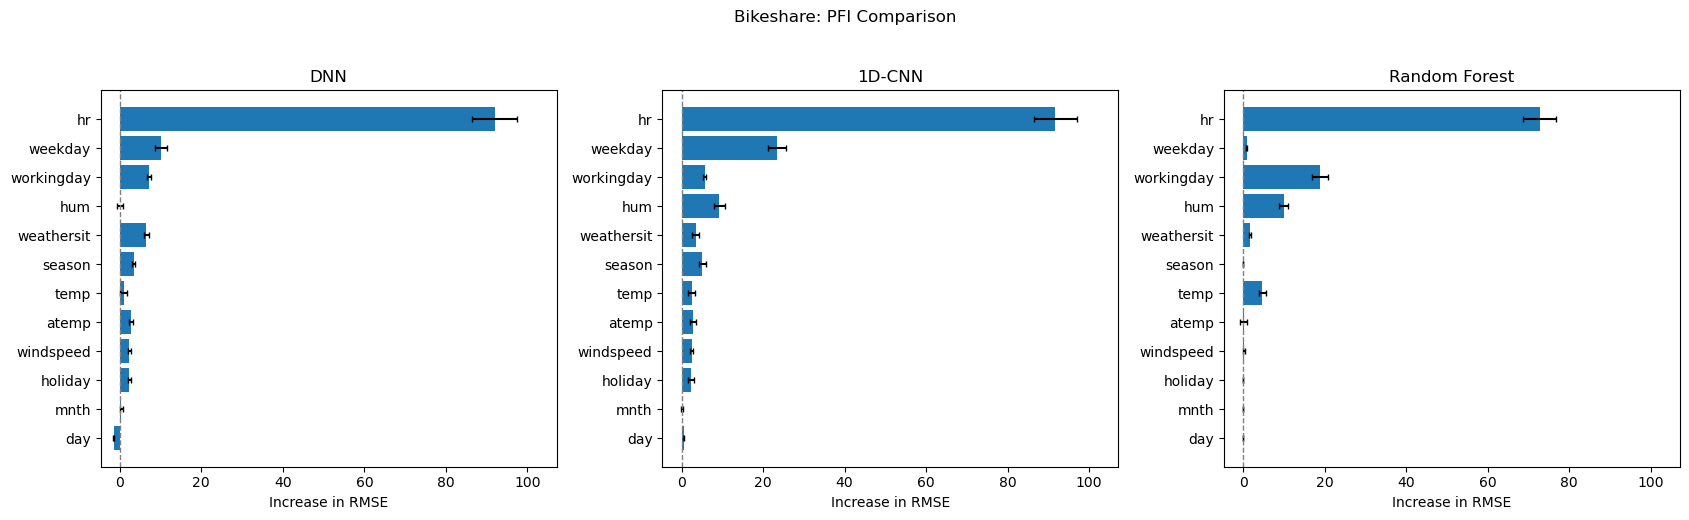

In [83]:
# Common feature order based on mean PFI
pfi_feature_order = (
    bike_pfi_all_df
    .groupby('Feature')['Importance']
    .mean()
    .sort_values()
    .index
)

pfi_min = (
    bike_pfi_all_df['Importance']
    - bike_pfi_all_df['Std']
).min()

pfi_max = (
    bike_pfi_all_df['Importance']
    + bike_pfi_all_df['Std']
).max()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, model_name in zip(axes, bike_predictors):
    result = (
        bike_pfi_all_df[
            bike_pfi_all_df['Model'] == model_name
        ]
        .set_index('Feature')
        .reindex(pfi_feature_order)
    )

    ax.barh(
        result.index,
        result['Importance'],
        xerr=result['Std'],
        capsize=2
    )

    ax.axvline(
        0, color='gray',
        linestyle='--', linewidth=1
    )

    ax.set_title(model_name)
    ax.set_xlabel('Increase in RMSE')
    ax.set_xlim(min(0, pfi_min) - 3, pfi_max * 1.1)

plt.suptitle('Bikeshare: PFI Comparison', y=1.03)
plt.tight_layout()
plt.show()

#### 3.7.2. SHAP Analysis

In [84]:
import shap

rng = np.random.default_rng(42)

# Common background and explanation samples
background_idx = rng.choice(
    len(X_train_explain),
    size=20,
    replace=False
)

explain_idx = rng.choice(
    len(X_test_explain),
    size=30,
    replace=False
)

X_background = X_train_explain.iloc[
    background_idx
].to_numpy(dtype=float)

X_explain = X_test_explain.iloc[
    explain_idx
].to_numpy(dtype=float)

# Shared masker
masker = shap.maskers.Independent(
    X_background
)

bike_shap_values = {}
bike_shap_results = []

for model_name, predict_fn in bike_predictors.items():
    print(f"Calculating SHAP: {model_name}")

    explainer = shap.Explainer(
        predict_fn,
        masker,
        algorithm='permutation'
    )

    explanation = explainer(
        X_explain,
        max_evals=3 * (2 * len(bike_original_features) + 1),
        batch_size=64,
        silent=True
    )

    bike_shap_values[model_name] = explanation

    values = np.asarray(explanation.values)

    if values.shape != X_explain.shape:
        raise ValueError(
            f"Unexpected SHAP shape for {model_name}: "
            f"{values.shape}"
        )

    mean_abs_shap = np.abs(values).mean(axis=0)

    for feature, importance in zip(
        bike_original_features,
        mean_abs_shap
    ):
        bike_shap_results.append({
            'Model': model_name,
            'Feature': feature,
            'Mean |SHAP|': importance
        })

    print(f"{model_name} SHAP completed.")

bike_shap_all_df = pd.DataFrame(bike_shap_results)

for model_name in bike_predictors:
    print(f"\n=== {model_name} SHAP ===")

    result = (
        bike_shap_all_df[
            bike_shap_all_df['Model'] == model_name
        ]
        .sort_values('Mean |SHAP|', ascending=False)
    )

    print(
        result[['Feature', 'Mean |SHAP|']]
        .round(4).to_string(index=False)
    )

Calculating SHAP: DNN
DNN SHAP completed.
Calculating SHAP: 1D-CNN
1D-CNN SHAP completed.
Calculating SHAP: Random Forest
Random Forest SHAP completed.

=== DNN SHAP ===
   Feature  Mean |SHAP|
        hr      74.7022
       day      37.6149
     atemp      16.7081
weathersit      14.0975
      temp      11.7069
       hum      11.4463
   weekday      11.0881
      mnth      10.7882
workingday       7.0700
    season       4.2145
 windspeed       3.7459
   holiday       0.5470

=== 1D-CNN SHAP ===
   Feature  Mean |SHAP|
        hr      63.8346
      temp      23.9832
       hum      17.1386
    season      13.9731
     atemp      11.5268
      mnth      10.7368
   weekday       9.8814
weathersit       8.7545
workingday       5.3937
       day       4.8414
 windspeed       4.0976
   holiday       0.7282

=== Random Forest SHAP ===
   Feature  Mean |SHAP|
        hr      61.9389
     atemp      35.9397
       hum      18.4669
       day      14.3442
      temp      13.9115
workingday   

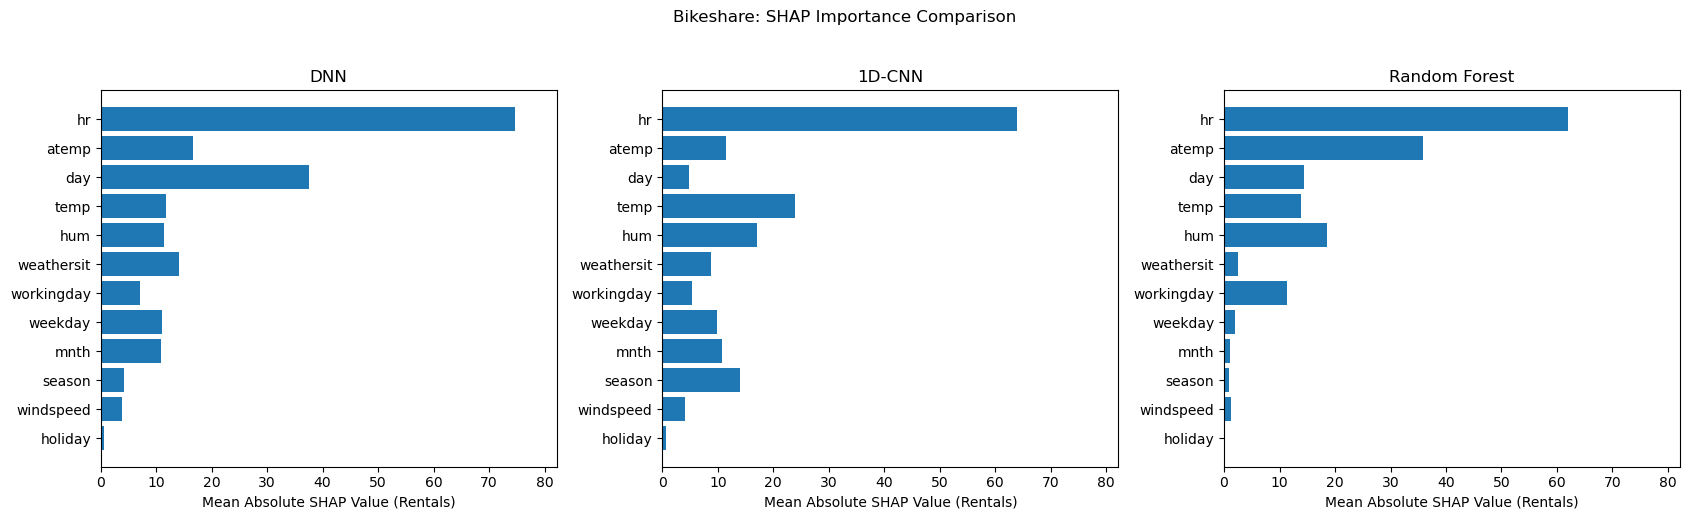

In [85]:
# Common feature order based on mean SHAP importance
shap_feature_order = (
    bike_shap_all_df
    .groupby('Feature')['Mean |SHAP|']
    .mean()
    .sort_values()
    .index
)

shap_max = bike_shap_all_df['Mean |SHAP|'].max()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, model_name in zip(axes, bike_predictors):
    result = (
        bike_shap_all_df[
            bike_shap_all_df['Model'] == model_name
        ]
        .set_index('Feature')
        .reindex(shap_feature_order)
    )

    ax.barh(
        result.index,
        result['Mean |SHAP|']
    )

    ax.set_title(model_name)
    ax.set_xlabel('Mean Absolute SHAP Value (Rentals)')
    ax.set_xlim(0, shap_max * 1.1)

plt.suptitle(
    'Bikeshare: SHAP Importance Comparison',
    y=1.03
)

plt.tight_layout()
plt.show()

#### 3.7.3. PFI and SHAP Comparison

세 모델에서 산출한 PFI와 SHAP의 상위 5개 변수를 비교한다.

PFI는 변수 교란에 따른 RMSE 증가량을 나타내고 SHAP은 기준 예측값에 대한 평균 절대 기여도를 나타낸다. 따라서 두 방법의 수치를 직접 비교하기보다는 변수 중요도 순위와 모델 간 공통점을 중심으로 해석한다.

In [86]:
from IPython.display import display

# Compare PFI and SHAP rankings side by side
comparison_data = {'Rank': range(1, 6)}

for model_name in bike_predictors:
    pfi_rank = (
        bike_pfi_all_df[
            bike_pfi_all_df['Model'] == model_name
        ]
        .sort_values('Importance', ascending=False)
        .head(5)['Feature']
        .tolist()
    )

    shap_rank = (
        bike_shap_all_df[
            bike_shap_all_df['Model'] == model_name
        ]
        .sort_values('Mean |SHAP|', ascending=False)
        .head(5)['Feature']
        .tolist()
    )

    comparison_data[(model_name, 'PFI')] = pfi_rank
    comparison_data[(model_name, 'SHAP')] = shap_rank

# Create compact comparison table
bike_importance_comparison = pd.DataFrame(
    comparison_data
).set_index('Rank')

bike_importance_comparison.columns = pd.MultiIndex.from_tuples(
    bike_importance_comparison.columns,
    names=['Model', 'Method']
)

display(
    bike_importance_comparison.style
    .set_caption('Top 5 Important Features: PFI vs SHAP')
    .set_properties(**{
        'text-align': 'center',
        'padding': '8px 12px'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('text-align', 'center'),
                ('padding', '8px 12px')
            ]
        }
    ])
)

**Feature Importance Interpretation**

PFI와 SHAP 분석 결과, **시간대(`hr`)가 DNN, 1D-CNN, Random Forest 모두에서 가장 중요한 변수**로 나타났다. 두 분석 방법 모두 세 모델에서 `hr`을 중요도 1위로 평가했다. 이는 자전거 대여량 예측에서 시간대별 이용 패턴이 핵심적인 역할을 한다는 것을 보여준다.

다만 시간대 이외의 변수 중요도는 모델과 분석 방법에 따라 차이가 있었다.

- **DNN:** PFI에서는 `weekday`, `workingday`, `weathersit`이 상위 변수였으나, SHAP에서는 `day`, `atemp`, `weathersit`이 중요하게 나타났다.
- **1D-CNN:** PFI에서는 `weekday`, `hum`, `workingday`가 상위 변수였으나, SHAP에서는 `temp`, `season`, `atemp`가 상대적으로 높은 중요도를 보였다. 이는 시간대 외의 변수에 대한 평가가 분석 방법에 따라 달라질 수 있음을 보여준다.

- **Random Forest:** PFI에서는 `workingday`, `hum`, `temp`가 중요하게 나타났으며, SHAP에서는 `atemp`, `hum`, `temp`, `day`가 상위 변수에 포함되었다. 두 방법 모두 습도와 온도 관련 변수의 중요도를 높게 평가했지만, 근무일 여부(`workingday`)의 상대적 중요도에는 차이가 있었다.
 
또한 `day`처럼 PFI와 SHAP 사이에서 중요도 순위 차이가 크게 나타나는 변수는 두 설명 방법의 계산 원리뿐 아니라 다른 변수와의 상관관계, 시간에 따른 데이터 분포 변화 등의 영향을 받을 수 있다. 따라서 이러한 차이를 특정 모델의 구조적 특성만으로 해석하지 않는다.


이러한 차이는 PFI와 SHAP의 계산 방식이 서로 다르기 때문에 발생할 수 있다. PFI는 특정 변수를 교란했을 때 발생하는 예측 성능 저하를 측정하는 반면, SHAP은 기준 예측값에 대한 변수별 기여도를 추정한다. 또한 변수 간 상관관계와 모델의 비선형적 관계 학습 방식도 중요도 순위에 영향을 줄 수 있다.

종합하면 **세 모델은 모두 시간대를 핵심 예측 변수로 활용하지만 그 외 변수의 상대적 중요도는 모델 구조와 분석 방법에 따라 다르게 나타났다.** 따라서 변수 중요도를 해석할 때는 단일 방법의 순위에만 의존하기보다 PFI와 SHAP 결과를 함께 고려하는 것이 적절하다.

본 SHAP 분석은 제한된 테스트 표본을 이용한 근사 분석이므로 중요도 순위를 전체 데이터에 대한 확정적인 결과로 일반화하는 데에는 주의가 필요하다.

### 3.8. Conclusion

Bikeshare 대여량 예측을 위해 DNN, 1D-CNN, Random Forest를 학습하고 동일한 테스트 기간에서 성능을 비교하였다.

최종 테스트 결과 1D-CNN이 RMSE 49.3483, MAE 31.5472, R² 0.8306으로 가장 우수한 예측 성능을 기록하였다. DNN과 Random Forest의 R²는 각각 0.7515와 0.7200으로 나타났다.

PFI와 SHAP을 이용한 변수 중요도 분석에서는 세 모델 모두 시간대(`hr`)를 가장 중요한 변수로 평가하였다. 반면 그 외 변수의 중요도 순위는 모델과 설명 방법에 따라 차이가 있었다.

종합하면 본 실험에서는 1D-CNN의 예측 성능이 가장 우수했으며, 시간대 정보가 자전거 대여량 예측에서 핵심적인 역할을 한다는 점을 확인하였다.

다만 1D-CNN은 시계열 윈도우가 아닌 표 형식의 변수 배열에 합성곱을 적용한 모델이므로 일반적인 시계열 CNN과 동일하게 해석해서는 안 된다. 또한 중요도 분석은 제한된 표본을 기반으로 하므로 결과를 일반화하는 데 주의가 필요하다.